# Forecasting Models Comparison — All Input Combinations, 10-Day Evaluation

For every fold, each of the models is trained once and evaluated via 10 independent 24h recursive forecasts

### Data Fetch

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone

file_path = "../data/office12_fullop_dataframe.xlsx"

data = pd.read_excel(file_path)
data['timestamp'] = pd.to_datetime(data['timestamp'])
data.set_index('timestamp', inplace=True)

print(data.head())
print(data.shape)

                     day_name  month  t_in  consumption  t_out  sequence  \
timestamp                                                                  
2025-03-13 12:00:00  Thursday  March  21.4       136.25   20.7         0   
2025-03-13 13:00:00  Thursday  March  21.8       136.66   20.6         0   
2025-03-13 14:00:00  Thursday  March  22.0       137.70   20.0         0   
2025-03-13 15:00:00  Thursday  March  22.1       138.37   19.3         0   
2025-03-13 16:00:00  Thursday  March  22.2       141.35   18.2         0   

                     heating_mode  cooling_mode  
timestamp                                        
2025-03-13 12:00:00             0             0  
2025-03-13 13:00:00             0             0  
2025-03-13 14:00:00             0             0  
2025-03-13 15:00:00             0             0  
2025-03-13 16:00:00             0             0  
(5926, 8)


In [ ]:
data.drop(columns=['day_name'], inplace=True)
#data.drop(columns=['consumption_partially_full'], inplace=True)

data.drop(columns=['consumption_handled'], inplace=True, errors='ignore')
data['sequence_lag1'] = data['sequence'].shift(1)
data['heating_mode_lag1'] = data['heating_mode'].shift(1)
data['cooling_mode_lag1'] = data['cooling_mode'].shift(1)

months = data.index.month
data['sin_month'] = np.sin(2 * np.pi * (months - 1) / 12)
data['cos_month'] = np.cos(2 * np.pi * (months - 1) / 12)

hours = data.index.hour
data['hour'] = hours
data['sin_hour'] = np.sin(2 * np.pi * hours / 24)
data['cos_hour'] = np.cos(2 * np.pi * hours / 24)

data['h_int'] = data['heating_mode'] * data['cos_hour']
data['c_int'] = data['cooling_mode'] * data['cos_hour']
data['first_op_hour'] = ((data['sequence_lag1'] == 0) & (data['sequence'] == 1)).astype(int)

# Drop the rows with NaN values created by shifting
data = data.dropna()

# lags
for i in [1, 2, 3, 24]:
    data[f't_in_lag{i}'] = data['t_in'].shift(i)

data['t_out_lag1'] = data['t_out'].shift(1)

data['in_out_diff'] = data['t_in_lag1'] - data['t_out_lag1']
data['delta_t'] = data['t_in'] - data['t_in_lag1']

# Drop the rows with NaN values created by shifting
data_clean = data.dropna()

print(data_clean.shape)

data12, data12_clean = data, data_clean

(5901, 25)


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone

file_path = "../data/office35_fullop_dataframe.xlsx"

data = pd.read_excel(file_path)
data['timestamp'] = pd.to_datetime(data['timestamp'])
data.set_index('timestamp', inplace=True)

print(data.head())
print(data.shape)
print(data['cooling_mode'].value_counts())

                      day_name     month  t_in  consumption  t_out  sequence  \
timestamp                                                                      
2024-11-27 11:00:00  Wednesday  November  22.7         0.00   17.2         0   
2024-11-27 12:00:00  Wednesday  November  23.2         0.01   17.7         0   
2024-11-27 13:00:00  Wednesday  November  23.5         0.00   18.0         0   
2024-11-27 14:00:00  Wednesday  November  23.7         0.00   17.4         0   
2024-11-27 15:00:00  Wednesday  November  23.6         0.00   16.2         0   

                     heating_mode  cooling_mode  
timestamp                                        
2024-11-27 11:00:00             0             0  
2024-11-27 12:00:00             0             0  
2024-11-27 13:00:00             0             0  
2024-11-27 14:00:00             0             0  
2024-11-27 15:00:00             0             0  
(8471, 8)
cooling_mode
0    7660
1     811
Name: count, dtype: int64


In [ ]:
data.drop(columns=['day_name'], inplace=True)

data.drop(columns=['consumption_handled'], inplace=True, errors='ignore')
data['sequence_lag1'] = data['sequence'].shift(1)
data['heating_mode_lag1'] = data['heating_mode'].shift(1)
data['cooling_mode_lag1'] = data['cooling_mode'].shift(1)

months = data.index.month
data['sin_month'] = np.sin(2 * np.pi * (months - 1) / 12)
data['cos_month'] = np.cos(2 * np.pi * (months - 1) / 12)

hours = data.index.hour
data['hour'] = hours
data['sin_hour'] = np.sin(2 * np.pi * hours / 24)
data['cos_hour'] = np.cos(2 * np.pi * hours / 24)

# Drop the rows with NaN values created by shifting
data = data.dropna()

# lags
for i in [1, 2, 3, 24]:
    data[f't_in_lag{i}'] = data['t_in'].shift(i)

data['t_out_lag1'] = data['t_out'].shift(1)

#data['in_out_diff'] = data['t_in_lag1'] - data['t_out_lag1']
data['delta_t'] = data['t_in'] - data['t_in_lag1']

# Drop the rows with NaN values created by shifting
data_clean = data.dropna()

print(data_clean.shape)

data35, data35_clean = data, data_clean

(8446, 21)


# Office 12

### Data Fetch

In [ ]:
data_clean = data12_clean
data_clean.index = pd.to_datetime(data_clean.index)

split_date = '2025-09-01'
train_df = data_clean.loc[data_clean.index < split_date]
test_df = data_clean.loc[data_clean.index >= split_date]

print(f"Training starts: {train_df.index[0]} and ends: {train_df.index[-1]}. The total length is {len(train_df)}")
print(f"Test data starts: {test_df.index[0]} and ends: {test_df.index[-1]}. The total length is {len(test_df)}")

# Each entry below is a training cutoff (expanding-window end-point)
fold_train_ends = [
                                            '2025-05-20 23:00',
    '2025-05-30 23:00', '2025-06-10 23:00', '2025-06-20 23:00',
    '2025-06-30 23:00', '2025-07-10 23:00', '2025-07-20 23:00',
    '2025-07-30 23:00', '2025-08-10 23:00', '2025-08-20 23:00',
]

EVAL_OFFSETS = list(range(1, 11))

def eval_starts(train_end, offsets=EVAL_OFFSETS):
    cutoff_date = pd.Timestamp(train_end).normalize()
    return [(cutoff_date + pd.Timedelta(days=off)).strftime('%Y-%m-%d 00:00') for off in offsets]

# Safety check: no evaluation day may fall on/after the train/test split.
for train_end in fold_train_ends:
    for test_start in eval_starts(train_end):
        assert (
            pd.Timestamp(test_start) < pd.Timestamp(split_date)
        ), f"evaluation day {test_start} (from fold {train_end}) falls on/after the train/test split"

horizon = 24
target_col = 't_in'
print(f"Number of folds (training sessions): {len(fold_train_ends)}")
print(f"Number of evaluation days per fold: {len(EVAL_OFFSETS)}")

Training starts: 2025-03-14 13:00:00 and ends: 2025-08-31 23:00:00. The total length is 4091
Test data starts: 2025-09-01 00:00:00 and ends: 2025-11-15 09:00:00. The total length is 1810
Number of folds (training sessions): 10
Number of evaluation days per fold: 10


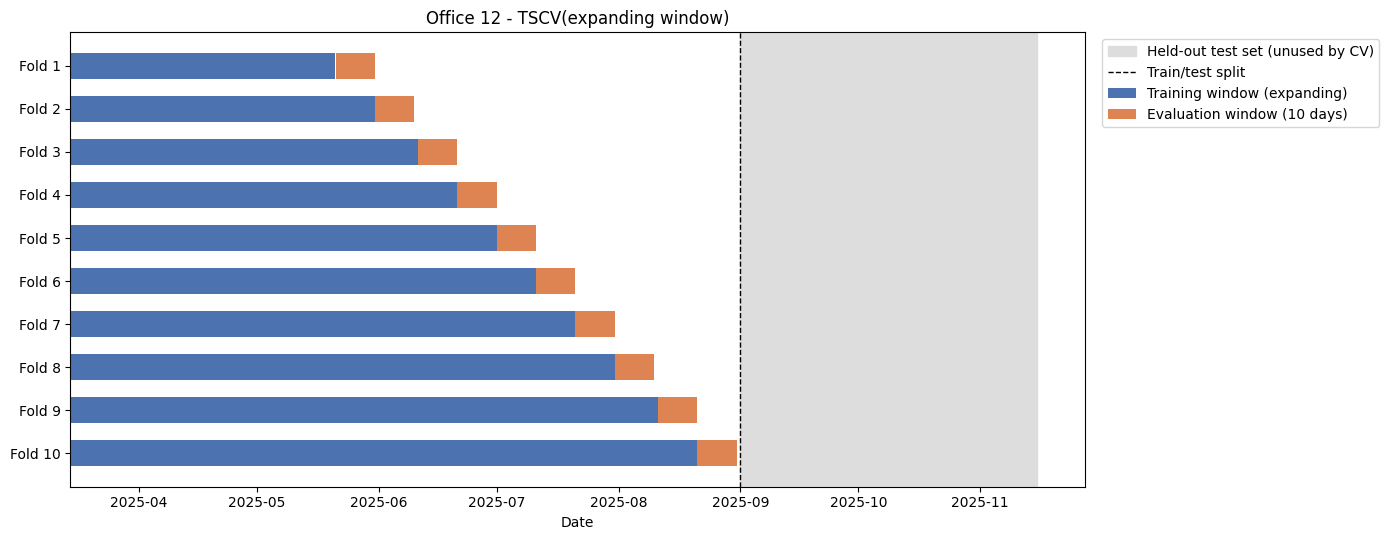

In [26]:
fig, ax = plt.subplots(figsize=(14, 0.4 * len(fold_train_ends) + 1.5))

train_start = data_clean.index[0]
test_end = data_clean.index[-1]

# Held-out test set, not touched by any CV fold.
ax.axvspan(pd.Timestamp(split_date), test_end, color="#DDDDDD", zorder=0,
           label="Held-out test set (unused by CV)")

for i, train_end in enumerate(fold_train_ends):
    train_end_ts = pd.Timestamp(train_end)
    eval_days = eval_starts(train_end)
    eval_start_ts = pd.Timestamp(eval_days[0])
    eval_end_ts = pd.Timestamp(eval_days[-1]) + pd.Timedelta(hours=horizon)

    train_width = (train_end_ts - train_start) / pd.Timedelta(days=1)
    eval_width = (eval_end_ts - eval_start_ts) / pd.Timedelta(days=1)

    ax.barh(i, train_width, left=train_start, height=0.6, color="#4C72B0",
            label="Training window (expanding)" if i == 0 else None)
    ax.barh(i, eval_width, left=eval_start_ts, height=0.6, color="#DD8452",
            label="Evaluation window (10 days)" if i == 0 else None)

ax.set_yticks(range(len(fold_train_ends)))
ax.set_yticklabels([f"Fold {i + 1}" for i in range(len(fold_train_ends))])
ax.invert_yaxis()
ax.axvline(pd.Timestamp(split_date), color="black", linestyle="--", linewidth=1,
           label="Train/test split")
ax.set_xlabel("Date")
ax.set_title("Office 12 - TSCV(expanding window)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Feature-input combinations

In [27]:
base_features = ['t_in_lag1', 't_in_lag2', 't_in_lag3', 't_out', 't_out_lag1','cooling_mode']

combos = {
    'Base':                                    base_features,
    '+t_in_lag24':                             base_features + ['t_in_lag24'],
    '+sin/cos_hour':                           base_features + ['sin_hour', 'cos_hour'],
    '+heat/cool_lag1':                         base_features + ['cooling_mode_lag1'],
    '+t_in_lag24+sin/cos_hour':                base_features + ['t_in_lag24', 'sin_hour', 'cos_hour'],
    '+t_in_lag24+heat/cool_lag1':              base_features + ['t_in_lag24', 'cooling_mode_lag1'],
    '+sin/cos_hour+heat/cool_lag1':            base_features + ['sin_hour', 'cos_hour', 'cooling_mode_lag1'],
    '+t_in_lag24+sin/cos_hour+heat/cool_lag1': base_features + ['t_in_lag24', 'sin_hour', 'cos_hour', 'cooling_mode_lag1'],
}

## Recursive Forecast function

In [ ]:
def run_cv_all_days(model_factory, feature_cols, label, fit_fn=None, folds=None,
                     verbose_folds=True, verbose_summary=True):
    """Walk-forward CV: each fold trains ONE model on fold_train_ends[k], 
        then evaluates that same model via 10 independent 24h recursive forecasts """
    if fit_fn is None:
        fit_fn = lambda m, X, y: m.fit(X, y)
    if folds is None:
        folds = fold_train_ends

    if verbose_summary:
        print(f"\n=== {label} ===")
    fold_maes = []

    for fold_idx, train_end in enumerate(folds):
        cv_train = data_clean[:train_end]
        model = model_factory()
        fit_fn(model, cv_train[feature_cols], cv_train[target_col])

        day_maes = []
        for test_start in eval_starts(train_end):
            start_idx = data_clean.index.get_loc(test_start)
            session_df = data_clean.iloc[start_idx: start_idx + horizon]
            actuals = session_df[target_col].values

            hist = list(data_clean.iloc[start_idx - 24: start_idx][target_col].values)
            preds = []
            for i in range(len(session_df)):
                row = session_df.iloc[i:i + 1].copy()
                (row['t_in_lag1'], row['t_in_lag2'], row['t_in_lag3'], row['t_in_lag24']) = (
                    hist[-1], hist[-2], hist[-3], hist[-24]
                )
                p = model.predict(row[feature_cols])[0]
                preds.append(p)
                hist.append(p)

            day_maes.append(mean_absolute_error(actuals, preds))

        fold_mae = np.mean(day_maes)
        fold_maes.append(fold_mae)
        if verbose_folds:
            print(f"Fold {fold_idx + 1} (train through {train_end[:10]}): MAE = {fold_mae:.3f}\u00b0C")

    final_mae = np.mean(fold_maes)
    if verbose_summary:
        print(f"--- Final MAE (average over {len(fold_maes)} folds) = {final_mae:.3f}\u00b0C ---")
    return final_mae


## 1. Linear Regression models

In [29]:
lr_results = {}
for name, feats in combos.items():
    lr_results[name] = run_cv_all_days(lambda: LinearRegression(), feats, f"Linear Regression \u2014 {name}")


=== Linear Regression — Base ===
Fold 1 (train through 2025-05-20): MAE = 0.355°C
Fold 2 (train through 2025-05-30): MAE = 0.718°C
Fold 3 (train through 2025-06-10): MAE = 0.839°C
Fold 4 (train through 2025-06-20): MAE = 0.413°C
Fold 5 (train through 2025-06-30): MAE = 0.647°C
Fold 6 (train through 2025-07-10): MAE = 0.573°C
Fold 7 (train through 2025-07-20): MAE = 0.780°C
Fold 8 (train through 2025-07-30): MAE = 0.444°C
Fold 9 (train through 2025-08-10): MAE = 0.629°C
Fold 10 (train through 2025-08-20): MAE = 0.592°C
--- Final MAE (average over 10 folds) = 0.599°C ---

=== Linear Regression — +t_in_lag24 ===
Fold 1 (train through 2025-05-20): MAE = 0.312°C
Fold 2 (train through 2025-05-30): MAE = 0.593°C
Fold 3 (train through 2025-06-10): MAE = 0.659°C
Fold 4 (train through 2025-06-20): MAE = 0.451°C
Fold 5 (train through 2025-06-30): MAE = 0.587°C
Fold 6 (train through 2025-07-10): MAE = 0.587°C
Fold 7 (train through 2025-07-20): MAE = 0.594°C
Fold 8 (train through 2025-07-30): MAE 

## 2. LightGBM models

In [30]:
def lgb_constraint(col):
    if col == 'heating_mode':
        return 1
    if col == 'cooling_mode':
        return -1
    return 0

def make_lgb_factory(feats):
    constraints = [lgb_constraint(c) for c in feats]
    return lambda: lgb.LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        monotone_constraints=constraints,
        boosting_type='gbdt',
        importance_type='gain',
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    )

def lgb_fit(m, X, y):
    m.fit(X, y, eval_set=[(X, y)], eval_metric='mae',
          callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)])

lgbm_results = {}
for name, feats in combos.items():
    lgbm_results[name] = run_cv_all_days(make_lgb_factory(feats), feats, f"LightGBM \u2014 {name}", fit_fn=lgb_fit)


=== LightGBM — Base ===
Fold 1 (train through 2025-05-20): MAE = 0.548°C
Fold 2 (train through 2025-05-30): MAE = 1.120°C
Fold 3 (train through 2025-06-10): MAE = 0.741°C
Fold 4 (train through 2025-06-20): MAE = 0.697°C
Fold 5 (train through 2025-06-30): MAE = 0.525°C
Fold 6 (train through 2025-07-10): MAE = 0.496°C
Fold 7 (train through 2025-07-20): MAE = 0.853°C
Fold 8 (train through 2025-07-30): MAE = 0.585°C
Fold 9 (train through 2025-08-10): MAE = 0.480°C
Fold 10 (train through 2025-08-20): MAE = 0.766°C
--- Final MAE (average over 10 folds) = 0.681°C ---

=== LightGBM — +t_in_lag24 ===
Fold 1 (train through 2025-05-20): MAE = 0.574°C
Fold 2 (train through 2025-05-30): MAE = 1.119°C
Fold 3 (train through 2025-06-10): MAE = 0.699°C
Fold 4 (train through 2025-06-20): MAE = 0.597°C
Fold 5 (train through 2025-06-30): MAE = 0.445°C
Fold 6 (train through 2025-07-10): MAE = 0.489°C
Fold 7 (train through 2025-07-20): MAE = 0.823°C
Fold 8 (train through 2025-07-30): MAE = 0.442°C
Fold 9 (

In [31]:
summary = pd.DataFrame({
    'LightGBM': pd.Series(lgbm_results),
    'LR': pd.Series(lr_results),
}).loc[list(combos.keys())]

summary.round(3)

,LightGBM,LR
Base,0.681,0.599
+t_in_lag24,0.619,0.514
+sin/cos_hour,0.638,0.591
+heat/cool_lag1,0.632,0.453
+t_in_lag24+sin/cos_hour,0.599,0.518
+t_in_lag24+heat/cool_lag1,0.624,0.440
+sin/cos_hour+heat/cool_lag1,0.616,0.444
+t_in_lag24+sin/cos_hour+heat/cool_lag1,0.604,0.444


In [ ]:
# Best input combo
best_combo_name = '+sin/cos_hour+heat/cool_lag1' 
feats = combos[best_combo_name]
print(f"Using combo: {best_combo_name}  ({len(feats)} features)")

Using combo: +sin/cos_hour+heat/cool_lag1  (9 features)


## 2b. LightGBM hyperparameter tuning

Basic Optuna search on top of the input combo selected above (feats): num_leaves,
min_child_samples, and learning_rate are tuned

In [ ]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def lgb_objective(trial):
    num_leaves = trial.suggest_int('num_leaves', 15, 63)
    min_child_samples = trial.suggest_int('min_child_samples', 5, 50)
    learning_rate = trial.suggest_float('learning_rate', 0.02, 0.15, log=True)

    constraints = [lgb_constraint(c) for c in feats]
    factory = lambda: lgb.LGBMRegressor(
        n_estimators=1000,
        num_leaves=num_leaves,
        min_child_samples=min_child_samples,
        learning_rate=learning_rate,
        max_depth=-1,
        monotone_constraints=constraints,
        boosting_type='gbdt',
        importance_type='gain',
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    )
    return run_cv_all_days(factory, feats, f"trial {trial.number}", fit_fn=lgb_fit,
                            verbose_folds=False, verbose_summary=False)


study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study.enqueue_trial({'num_leaves': 31, 'min_child_samples': 20, 'learning_rate': 0.05})
study.optimize(lgb_objective, n_trials=20, show_progress_bar=False)

print(f"Best recursive MAE (search objective): {study.best_value:.4f}\u00b0C")
print("Best params:", study.best_params)

Best recursive MAE (search objective): 0.6162°C
Best params: {'num_leaves': 31, 'min_child_samples': 20, 'learning_rate': 0.05}


In [34]:
constraints = [lgb_constraint(c) for c in feats]
best_lgb_factory = lambda: lgb.LGBMRegressor(
    n_estimators=1000,
    num_leaves=study.best_params['num_leaves'],
    min_child_samples=study.best_params['min_child_samples'],
    learning_rate=study.best_params['learning_rate'],
    max_depth=-1,
    monotone_constraints=constraints,
    boosting_type='gbdt',
    importance_type='gain',
    random_state=12,
    n_jobs=-1,
    verbosity=-1,
)
lgbm_tuned_mae = run_cv_all_days(best_lgb_factory, feats, "LightGBM (Optuna-tuned)", fit_fn=lgb_fit)

print(f"\nUntuned LightGBM ({best_combo_name}): {lgbm_results[best_combo_name]:.4f}\u00b0C  (recursive CV)")
print(f"Tuned   LightGBM ({best_combo_name}): {lgbm_tuned_mae:.4f}\u00b0C  (recursive CV)")


=== LightGBM (Optuna-tuned) ===
Fold 1 (train through 2025-05-20): MAE = 0.506°C
Fold 2 (train through 2025-05-30): MAE = 1.111°C
Fold 3 (train through 2025-06-10): MAE = 0.621°C
Fold 4 (train through 2025-06-20): MAE = 0.638°C
Fold 5 (train through 2025-06-30): MAE = 0.515°C
Fold 6 (train through 2025-07-10): MAE = 0.430°C
Fold 7 (train through 2025-07-20): MAE = 0.807°C
Fold 8 (train through 2025-07-30): MAE = 0.447°C
Fold 9 (train through 2025-08-10): MAE = 0.526°C
Fold 10 (train through 2025-08-20): MAE = 0.560°C
--- Final MAE (average over 10 folds) = 0.616°C ---

Untuned LightGBM (+sin/cos_hour+heat/cool_lag1): 0.6162°C  (recursive CV)
Tuned   LightGBM (+sin/cos_hour+heat/cool_lag1): 0.6162°C  (recursive CV)


### Feature importance

In [ ]:
# Fit the tuned LightGBM once on all data through the train/test split (same convention as the Final Evaluation section)
final_lgb = best_lgb_factory()
lgb_fit(final_lgb, train_df[feats], train_df[target_col])

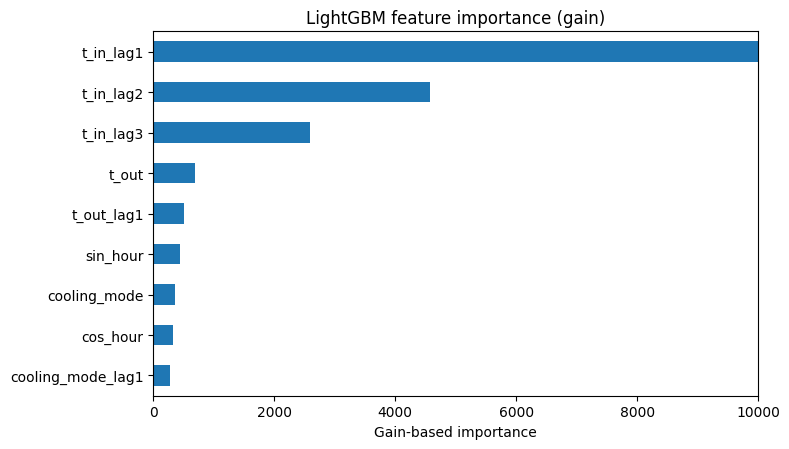

In [36]:
importances = pd.Series(final_lgb.feature_importances_, index=feats).sort_values(ascending=True)

plt.figure(figsize=(8, 0.4 * len(feats) + 1))
importances.plot(kind='barh')
plt.xlabel('Gain-based importance')
plt.xlim(0,  10000)
plt.title('LightGBM feature importance (gain)')
plt.tight_layout()
plt.show()

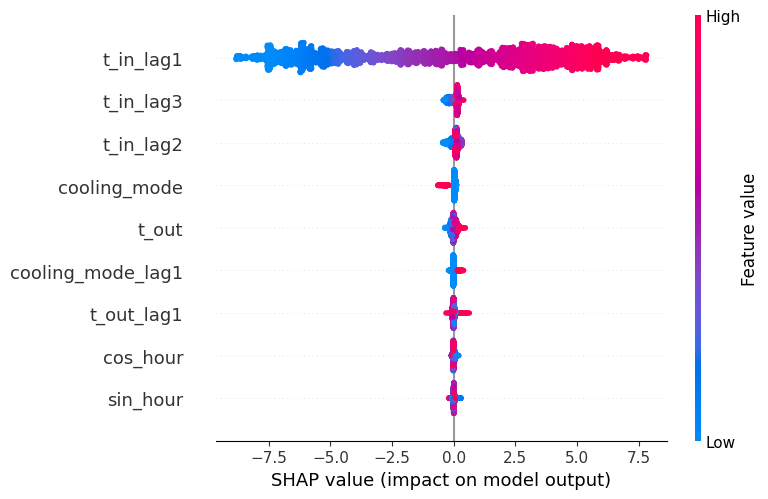

In [37]:
import shap

explainer = shap.TreeExplainer(final_lgb)
shap_values = explainer.shap_values(train_df[feats])

shap.summary_plot(shap_values, train_df[feats], show=False)
plt.tight_layout()
plt.show()

## 3. Neural Network (MLP) models

### Random-search NN hyperparameters

In [38]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

mode_cols = {'heating_mode', 'cooling_mode', 'heating_mode_lag1', 'cooling_mode_lag1'}
minmax_cols = {'sin_hour', 'cos_hour'}

def make_nn_fixed_factory(feats, hidden_layer_sizes, alpha, learning_rate_init):
    std_feats = [c for c in feats if c not in mode_cols and c not in minmax_cols]
    minmax_feats = [c for c in feats if c in minmax_cols]
    pass_feats = [c for c in feats if c in mode_cols]

    preprocessor = ColumnTransformer([
        ('std', StandardScaler(), std_feats),
        ('minmax', MinMaxScaler(), minmax_feats),
        ('pass', 'passthrough', pass_feats),
    ])
    template = Pipeline([
        ('preprocessor', preprocessor),
        ('mlp', MLPRegressor(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha,
                              learning_rate_init=learning_rate_init,
                              max_iter=500, early_stopping=True, random_state=42)),
    ])
    return lambda: clone(template)

In [ ]:
# Random search over NN hyperparameters
N_NN_CANDIDATES = 16
rng = np.random.default_rng(42)

nn_candidates = []
for _ in range(N_NN_CANDIDATES):
    layer1 = int(rng.integers(6, 25))
    if rng.choice([1, 2]) == 1:
        hidden_layer_sizes = (layer1,)
    else:
        layer2 = max(1, round(layer1 * rng.uniform(0.5, 0.8)))
        hidden_layer_sizes = (layer1, layer2)
    alpha = float(10 ** rng.uniform(np.log10(1e-5), np.log10(1e-1)))
    learning_rate_init = float(10 ** rng.uniform(np.log10(1e-4), np.log10(1e-2)))
    nn_candidates.append((hidden_layer_sizes, alpha, learning_rate_init))

print(f"=== {len(nn_candidates)} randomly-drawn NN hyperparameter candidates ===")
for c in nn_candidates:
    print(f"  hidden_layer_sizes={c[0]!s:>10}  alpha={c[1]:.2e}  learning_rate_init={c[2]:.2e}")

=== 16 randomly-drawn NN hyperparameter candidates ===
  hidden_layer_sizes=    (7, 4)  alpha=2.72e-02  learning_rate_init=2.48e-03
  hidden_layer_sizes=      (9,)  alpha=7.99e-02  learning_rate_init=3.33e-03
  hidden_layer_sizes=  (19, 10)  alpha=6.33e-04  learning_rate_init=5.52e-04
  hidden_layer_sizes=    (9, 6)  alpha=1.95e-02  learning_rate_init=7.71e-04
  hidden_layer_sizes=     (14,)  alpha=1.65e-03  learning_rate_init=1.34e-04
  hidden_layer_sizes=  (22, 15)  alpha=1.08e-02  learning_rate_init=5.12e-04
  hidden_layer_sizes=    (7, 5)  alpha=1.30e-02  learning_rate_init=2.45e-04
  hidden_layer_sizes=     (12,)  alpha=1.50e-05  learning_rate_init=2.04e-04
  hidden_layer_sizes=  (20, 14)  alpha=7.41e-02  learning_rate_init=4.48e-04
  hidden_layer_sizes=     (23,)  alpha=7.55e-04  learning_rate_init=2.39e-04
  hidden_layer_sizes=     (14,)  alpha=8.00e-04  learning_rate_init=2.84e-04
  hidden_layer_sizes=  (16, 10)  alpha=2.14e-02  learning_rate_init=2.51e-03
  hidden_layer_sizes=

### Evaluate each candidate (full walk-forward CV, same as LR/LightGBM)

In [40]:
nn_candidate_maes = []
for i, (hidden_layer_sizes, alpha, learning_rate_init) in enumerate(nn_candidates):
    factory = make_nn_fixed_factory(feats, hidden_layer_sizes, alpha, learning_rate_init)
    label = (f"NN candidate {i + 1}/{len(nn_candidates)} -- hidden_layer_sizes={hidden_layer_sizes}, "
             f"alpha={alpha:.2e}, learning_rate_init={learning_rate_init:.2e}")
    mae = run_cv_all_days(factory, feats, label, verbose_folds=False)
    nn_candidate_maes.append(mae)

best_idx = int(np.argmin(nn_candidate_maes))
o12_best_nn_hidden_layer_sizes, o12_best_nn_alpha, o12_best_nn_learning_rate_init = nn_candidates[best_idx]
nn_mae = nn_candidate_maes[best_idx]
print(f"\nBest NN candidate: hidden_layer_sizes={o12_best_nn_hidden_layer_sizes}, "
      f"alpha={o12_best_nn_alpha:.2e}, learning_rate_init={o12_best_nn_learning_rate_init:.2e}  "
      f"(MAE = {nn_mae:.3f}\u00b0C)")


=== NN candidate 1/16 -- hidden_layer_sizes=(7, 4), alpha=2.72e-02, learning_rate_init=2.48e-03 ===
--- Final MAE (average over 10 folds) = 11.234°C ---

=== NN candidate 2/16 -- hidden_layer_sizes=(9,), alpha=7.99e-02, learning_rate_init=3.33e-03 ===
--- Final MAE (average over 10 folds) = 32984.314°C ---

=== NN candidate 3/16 -- hidden_layer_sizes=(19, 10), alpha=6.33e-04, learning_rate_init=5.52e-04 ===
--- Final MAE (average over 10 folds) = 12.268°C ---

=== NN candidate 4/16 -- hidden_layer_sizes=(9, 6), alpha=1.95e-02, learning_rate_init=7.71e-04 ===
--- Final MAE (average over 10 folds) = 19204.335°C ---

=== NN candidate 5/16 -- hidden_layer_sizes=(14,), alpha=1.65e-03, learning_rate_init=1.34e-04 ===
--- Final MAE (average over 10 folds) = 12.776°C ---

=== NN candidate 6/16 -- hidden_layer_sizes=(22, 15), alpha=1.08e-02, learning_rate_init=5.12e-04 ===
--- Final MAE (average over 10 folds) = 80.204°C ---

=== NN candidate 7/16 -- hidden_layer_sizes=(7, 5), alpha=1.30e-02, 

### Final comparison for the chosen combo

In [41]:
comparison = pd.Series({
    'LR': lr_results[best_combo_name],
    'LightGBM': lgbm_results[best_combo_name],
    'NN': nn_mae,
}, name=f'MAE ({best_combo_name})')

comparison.round(3)

LR          0.444
LightGBM    0.616
NN          1.972
Name: MAE (+sin/cos_hour+heat/cool_lag1), dtype: float64

# Office 35

### Data Fetch

In [ ]:
data_clean = data35_clean
data_clean.index = pd.to_datetime(data_clean.index)

split_date = '2025-09-01'
train_df = data_clean.loc[data_clean.index < split_date]
test_df = data_clean.loc[data_clean.index >= split_date]

print(f"Training starts: {train_df.index[0]} and ends: {train_df.index[-1]}. The total length is {len(train_df)}")
print(f"Test data starts: {test_df.index[0]} and ends: {test_df.index[-1]}. The total length is {len(test_df)}")

# Each entry below is a training cutoff (expanding-window end-point)
fold_train_ends = [
    '2025-01-29 23:00', '2025-02-08 23:00', '2025-02-18 23:00',
    '2025-02-28 23:00', '2025-03-10 23:00', '2025-03-20 23:00',
    '2025-03-30 23:00', '2025-04-10 23:00', '2025-04-20 23:00',
                        '2025-05-10 23:00', '2025-05-20 23:00',
    '2025-05-30 23:00', '2025-06-10 23:00', '2025-06-20 23:00',
    '2025-06-30 23:00', '2025-07-10 23:00', '2025-07-20 23:00',
    '2025-07-30 23:00', '2025-08-10 23:00', '2025-08-20 23:00',
]

EVAL_OFFSETS = list(range(1, 11))

def eval_starts(train_end, offsets=EVAL_OFFSETS):
    cutoff_date = pd.Timestamp(train_end).normalize()
    return [(cutoff_date + pd.Timedelta(days=off)).strftime('%Y-%m-%d 00:00') for off in offsets]

# Safety check: no evaluation day may fall on/after the train/test split.
for train_end in fold_train_ends:
    for test_start in eval_starts(train_end):
        assert (
            pd.Timestamp(test_start) < pd.Timestamp(split_date)
        ), f"evaluation day {test_start} (from fold {train_end}) falls on/after the train/test split"

horizon = 24
target_col = 't_in'
print(f"Number of folds (training sessions): {len(fold_train_ends)}")
print(f"Number of evaluation days per fold: {len(EVAL_OFFSETS)}")

Training starts: 2024-11-28 12:00:00 and ends: 2025-08-31 23:00:00. The total length is 6636
Test data starts: 2025-09-01 00:00:00 and ends: 2025-11-15 09:00:00. The total length is 1810
Number of folds (training sessions): 20
Number of evaluation days per fold: 10


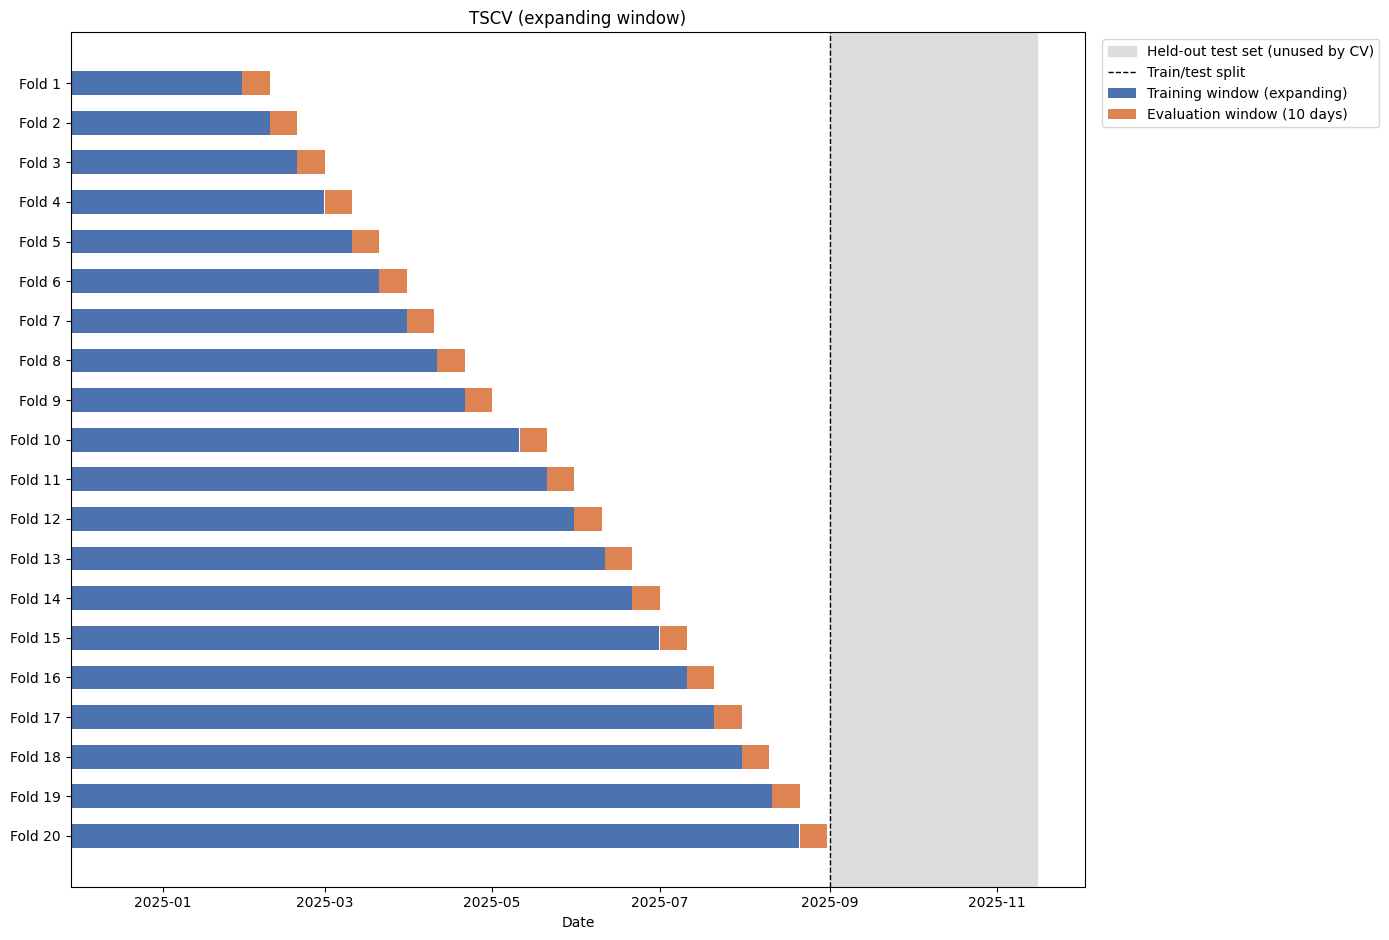

In [43]:
fig, ax = plt.subplots(figsize=(14, 0.4 * len(fold_train_ends) + 1.5))

train_start = data_clean.index[0]
test_end = data_clean.index[-1]

# Held-out test set, not touched by any CV fold.
ax.axvspan(pd.Timestamp(split_date), test_end, color="#DDDDDD", zorder=0,
           label="Held-out test set (unused by CV)")

for i, train_end in enumerate(fold_train_ends):
    train_end_ts = pd.Timestamp(train_end)
    eval_days = eval_starts(train_end)
    eval_start_ts = pd.Timestamp(eval_days[0])
    eval_end_ts = pd.Timestamp(eval_days[-1]) + pd.Timedelta(hours=horizon)

    train_width = (train_end_ts - train_start) / pd.Timedelta(days=1)
    eval_width = (eval_end_ts - eval_start_ts) / pd.Timedelta(days=1)

    ax.barh(i, train_width, left=train_start, height=0.6, color="#4C72B0",
            label="Training window (expanding)" if i == 0 else None)
    ax.barh(i, eval_width, left=eval_start_ts, height=0.6, color="#DD8452",
            label="Evaluation window (10 days)" if i == 0 else None)

ax.set_yticks(range(len(fold_train_ends)))
ax.set_yticklabels([f"Fold {i + 1}" for i in range(len(fold_train_ends))])
ax.invert_yaxis()
ax.axvline(pd.Timestamp(split_date), color="black", linestyle="--", linewidth=1,
           label="Train/test split")
ax.set_xlabel("Date")
ax.set_title("TSCV (expanding window)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Feature-input combinations

In [44]:
base_features = ['t_in_lag1', 't_in_lag2', 't_in_lag3', 't_out', 't_out_lag1',
                  'heating_mode', 'cooling_mode']

combos = {
    'Base':                                    base_features,
    '+t_in_lag24':                             base_features + ['t_in_lag24'],
    '+sin/cos_hour':                           base_features + ['sin_hour', 'cos_hour'],
    '+heat/cool_lag1':                         base_features + ['heating_mode_lag1', 'cooling_mode_lag1'],
    '+t_in_lag24+sin/cos_hour':                base_features + ['t_in_lag24', 'sin_hour', 'cos_hour'],
    '+t_in_lag24+heat/cool_lag1':              base_features + ['t_in_lag24', 'heating_mode_lag1', 'cooling_mode_lag1'],
    '+sin/cos_hour+heat/cool_lag1':            base_features + ['sin_hour', 'cos_hour', 'heating_mode_lag1', 'cooling_mode_lag1'],
    '+t_in_lag24+sin/cos_hour+heat/cool_lag1': base_features + ['t_in_lag24', 'sin_hour', 'cos_hour', 'heating_mode_lag1', 'cooling_mode_lag1'],
}

## Recursive Forecast (10-day evaluation per fold)

In [ ]:
def run_cv_all_days(model_factory, feature_cols, label, fit_fn=None, folds=None,
                     verbose_folds=True, verbose_summary=True):
    """Walk-forward CV: each fold trains ONE model on fold_train_ends[k], 
    then evaluates that same model via 10 independent 24h recursive forecasts """
    if fit_fn is None:
        fit_fn = lambda m, X, y: m.fit(X, y)
    if folds is None:
        folds = fold_train_ends

    if verbose_summary:
        print(f"\n=== {label} ===")
    fold_maes = []

    for fold_idx, train_end in enumerate(folds):
        cv_train = data_clean[:train_end]
        model = model_factory()
        fit_fn(model, cv_train[feature_cols], cv_train[target_col])

        day_maes = []
        for test_start in eval_starts(train_end):
            start_idx = data_clean.index.get_loc(test_start)
            session_df = data_clean.iloc[start_idx: start_idx + horizon]
            actuals = session_df[target_col].values

            hist = list(data_clean.iloc[start_idx - 24: start_idx][target_col].values)
            preds = []
            for i in range(len(session_df)):
                row = session_df.iloc[i:i + 1].copy()
                (row['t_in_lag1'], row['t_in_lag2'], row['t_in_lag3'], row['t_in_lag24']) = (
                    hist[-1], hist[-2], hist[-3], hist[-24]
                )
                p = model.predict(row[feature_cols])[0]
                preds.append(p)
                hist.append(p)

            day_maes.append(mean_absolute_error(actuals, preds))

        fold_mae = np.mean(day_maes)
        fold_maes.append(fold_mae)
        if verbose_folds:
            print(f"Fold {fold_idx + 1} (train through {train_end[:10]}): MAE = {fold_mae:.3f}\u00b0C")

    final_mae = np.mean(fold_maes)
    if verbose_summary:
        print(f"--- Final MAE (average over {len(fold_maes)} folds) = {final_mae:.3f}\u00b0C ---")
    return final_mae


## 1. Linear Regression models

In [46]:
lr_results = {}
for name, feats in combos.items():
    lr_results[name] = run_cv_all_days(lambda: LinearRegression(), feats, f"Linear Regression \u2014 {name}")


=== Linear Regression — Base ===
Fold 1 (train through 2025-01-29): MAE = 0.894°C
Fold 2 (train through 2025-02-08): MAE = 0.986°C
Fold 3 (train through 2025-02-18): MAE = 0.911°C
Fold 4 (train through 2025-02-28): MAE = 0.623°C
Fold 5 (train through 2025-03-10): MAE = 0.685°C
Fold 6 (train through 2025-03-20): MAE = 0.876°C
Fold 7 (train through 2025-03-30): MAE = 0.853°C
Fold 8 (train through 2025-04-10): MAE = 0.820°C
Fold 9 (train through 2025-04-20): MAE = 0.488°C
Fold 10 (train through 2025-05-10): MAE = 0.678°C
Fold 11 (train through 2025-05-20): MAE = 0.832°C
Fold 12 (train through 2025-05-30): MAE = 0.542°C
Fold 13 (train through 2025-06-10): MAE = 1.103°C
Fold 14 (train through 2025-06-20): MAE = 1.010°C
Fold 15 (train through 2025-06-30): MAE = 1.010°C
Fold 16 (train through 2025-07-10): MAE = 0.879°C
Fold 17 (train through 2025-07-20): MAE = 0.993°C
Fold 18 (train through 2025-07-30): MAE = 0.794°C
Fold 19 (train through 2025-08-10): MAE = 0.971°C
Fold 20 (train through 20

## 2. LightGBM models

In [47]:
def lgb_constraint(col):
    if col == 'heating_mode':
        return 1
    if col == 'cooling_mode':
        return -1
    return 0

def make_lgb_factory(feats):
    constraints = [lgb_constraint(c) for c in feats]
    return lambda: lgb.LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        monotone_constraints=constraints,
        boosting_type='gbdt',
        importance_type='gain',
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    )

def lgb_fit(m, X, y):
    m.fit(X, y, eval_set=[(X, y)], eval_metric='mae',
          callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)])

lgbm_results = {}
for name, feats in combos.items():
    lgbm_results[name] = run_cv_all_days(make_lgb_factory(feats), feats, f"LightGBM \u2014 {name}", fit_fn=lgb_fit)


=== LightGBM — Base ===
Fold 1 (train through 2025-01-29): MAE = 0.841°C
Fold 2 (train through 2025-02-08): MAE = 0.987°C
Fold 3 (train through 2025-02-18): MAE = 1.044°C
Fold 4 (train through 2025-02-28): MAE = 0.812°C
Fold 5 (train through 2025-03-10): MAE = 0.904°C
Fold 6 (train through 2025-03-20): MAE = 1.086°C
Fold 7 (train through 2025-03-30): MAE = 0.613°C
Fold 8 (train through 2025-04-10): MAE = 0.682°C
Fold 9 (train through 2025-04-20): MAE = 0.671°C
Fold 10 (train through 2025-05-10): MAE = 0.550°C
Fold 11 (train through 2025-05-20): MAE = 0.493°C
Fold 12 (train through 2025-05-30): MAE = 1.132°C
Fold 13 (train through 2025-06-10): MAE = 0.905°C
Fold 14 (train through 2025-06-20): MAE = 0.724°C
Fold 15 (train through 2025-06-30): MAE = 0.776°C
Fold 16 (train through 2025-07-10): MAE = 0.645°C
Fold 17 (train through 2025-07-20): MAE = 0.966°C
Fold 18 (train through 2025-07-30): MAE = 0.747°C
Fold 19 (train through 2025-08-10): MAE = 0.543°C
Fold 20 (train through 2025-08-20)

In [48]:
summary = pd.DataFrame({
    'LightGBM': pd.Series(lgbm_results),
    'LR': pd.Series(lr_results),
}).loc[list(combos.keys())]

summary.round(3)

,LightGBM,LR
Base,0.783,0.841
+t_in_lag24,0.736,0.704
+sin/cos_hour,0.672,0.798
+heat/cool_lag1,0.799,0.776
+t_in_lag24+sin/cos_hour,0.639,0.720
+t_in_lag24+heat/cool_lag1,0.736,0.652
+sin/cos_hour+heat/cool_lag1,0.690,0.680
+t_in_lag24+sin/cos_hour+heat/cool_lag1,0.641,0.639


In [ ]:
# Best input combo
best_combo_name = '+sin/cos_hour+heat/cool_lag1'
feats = combos[best_combo_name]
print(f"Using combo: {best_combo_name}  ({len(feats)} features)")

Using combo: +sin/cos_hour+heat/cool_lag1  (11 features)


## 2b. LightGBM hyperparameter tuning

Basic Optuna search on top of the input combo selected above (feats): num_leaves,
min_child_samples, and learning_rate are tuned

In [ ]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def lgb_objective(trial):
    num_leaves = trial.suggest_int('num_leaves', 15, 63)
    min_child_samples = trial.suggest_int('min_child_samples', 5, 50)
    learning_rate = trial.suggest_float('learning_rate', 0.02, 0.15, log=True)

    constraints = [lgb_constraint(c) for c in feats]
    factory = lambda: lgb.LGBMRegressor(
        n_estimators=1000,
        num_leaves=num_leaves,
        min_child_samples=min_child_samples,
        learning_rate=learning_rate,
        max_depth=-1,
        monotone_constraints=constraints,
        boosting_type='gbdt',
        importance_type='gain',
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    )
    return run_cv_all_days(factory, feats, f"trial {trial.number}", fit_fn=lgb_fit,
                            verbose_folds=False, verbose_summary=False)


study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study.enqueue_trial({'num_leaves': 31, 'min_child_samples': 20, 'learning_rate': 0.05})
study.optimize(lgb_objective, n_trials=20, show_progress_bar=False)

print(f"Best recursive MAE (search objective): {study.best_value:.4f}\u00b0C")
print("Best params:", study.best_params)

Best recursive MAE (search objective): 0.6523°C
Best params: {'num_leaves': 36, 'min_child_samples': 18, 'learning_rate': 0.06861811172897295}


In [51]:
constraints = [lgb_constraint(c) for c in feats]
best_lgb_factory = lambda: lgb.LGBMRegressor(
    n_estimators=1000,
    num_leaves=study.best_params['num_leaves'],
    min_child_samples=study.best_params['min_child_samples'],
    learning_rate=study.best_params['learning_rate'],
    max_depth=-1,
    monotone_constraints=constraints,
    boosting_type='gbdt',
    importance_type='gain',
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)
lgbm_tuned_mae = run_cv_all_days(best_lgb_factory, feats, "LightGBM (Optuna-tuned)", fit_fn=lgb_fit)

print(f"\nUntuned LightGBM ({best_combo_name}): {lgbm_results[best_combo_name]:.4f}\u00b0C  (recursive CV)")
print(f"Tuned   LightGBM ({best_combo_name}): {lgbm_tuned_mae:.4f}\u00b0C  (recursive CV)")


=== LightGBM (Optuna-tuned) ===
Fold 1 (train through 2025-01-29): MAE = 0.589°C
Fold 2 (train through 2025-02-08): MAE = 0.666°C
Fold 3 (train through 2025-02-18): MAE = 0.782°C
Fold 4 (train through 2025-02-28): MAE = 0.817°C
Fold 5 (train through 2025-03-10): MAE = 0.544°C
Fold 6 (train through 2025-03-20): MAE = 0.598°C
Fold 7 (train through 2025-03-30): MAE = 0.552°C
Fold 8 (train through 2025-04-10): MAE = 0.367°C
Fold 9 (train through 2025-04-20): MAE = 0.491°C
Fold 10 (train through 2025-05-10): MAE = 0.582°C
Fold 11 (train through 2025-05-20): MAE = 0.493°C
Fold 12 (train through 2025-05-30): MAE = 1.085°C
Fold 13 (train through 2025-06-10): MAE = 0.815°C
Fold 14 (train through 2025-06-20): MAE = 0.714°C
Fold 15 (train through 2025-06-30): MAE = 0.662°C
Fold 16 (train through 2025-07-10): MAE = 0.766°C
Fold 17 (train through 2025-07-20): MAE = 0.866°C
Fold 18 (train through 2025-07-30): MAE = 0.541°C
Fold 19 (train through 2025-08-10): MAE = 0.572°C
Fold 20 (train through 202

### Feature importance

In [ ]:
# Fit the tuned LightGBM once on all data through the train/test split (same convention as the Final Evaluation section)
final_lgb = best_lgb_factory()
lgb_fit(final_lgb, train_df[feats], train_df[target_col])

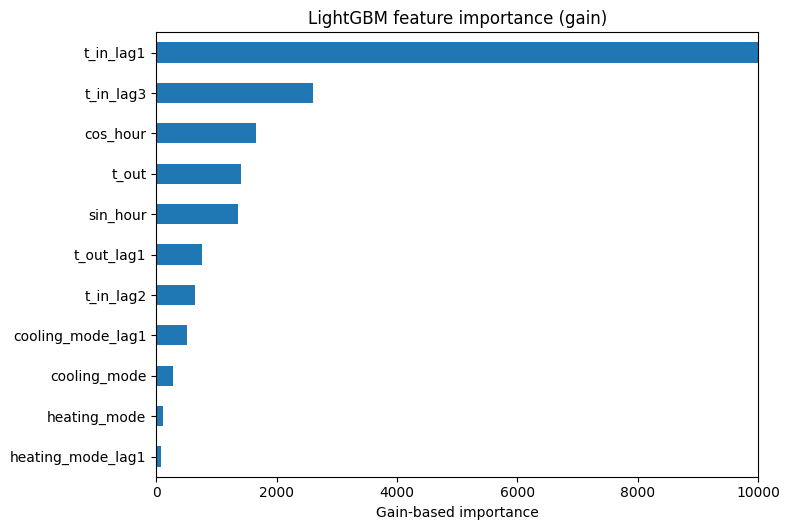

In [53]:
importances = pd.Series(final_lgb.feature_importances_, index=feats).sort_values(ascending=True)

plt.figure(figsize=(8, 0.4 * len(feats) + 1))
importances.plot(kind='barh')
plt.xlabel('Gain-based importance')
plt.xlim(0,  10000)
plt.title('LightGBM feature importance (gain)')
plt.tight_layout()
plt.show()

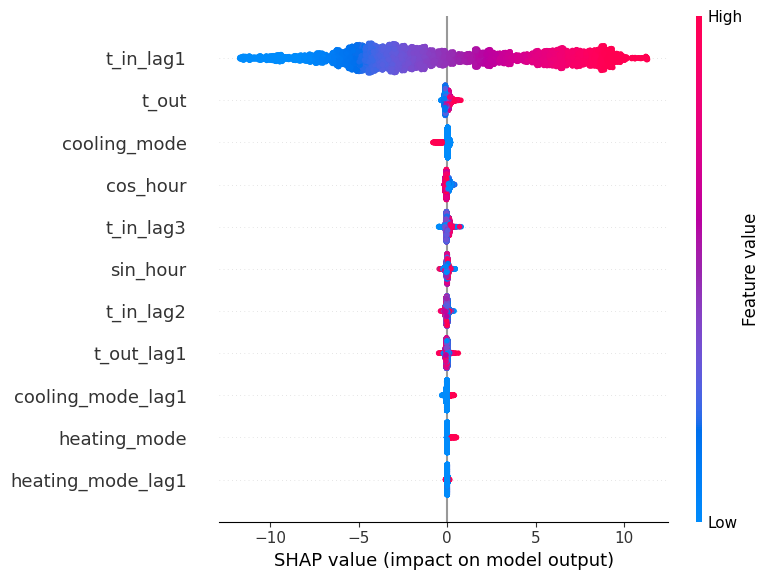

In [54]:
import shap

explainer = shap.TreeExplainer(final_lgb)
shap_values = explainer.shap_values(train_df[feats])

shap.summary_plot(shap_values, train_df[feats], show=False)
plt.tight_layout()
plt.show()

## 3. Neural Network (MLP) models

### Random-search NN hyperparameters

In [55]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

mode_cols = {'heating_mode', 'cooling_mode', 'heating_mode_lag1', 'cooling_mode_lag1'}
minmax_cols = {'sin_hour', 'cos_hour'}

def make_nn_fixed_factory(feats, hidden_layer_sizes, alpha, learning_rate_init):
    std_feats = [c for c in feats if c not in mode_cols and c not in minmax_cols]
    minmax_feats = [c for c in feats if c in minmax_cols]
    pass_feats = [c for c in feats if c in mode_cols]

    preprocessor = ColumnTransformer([
        ('std', StandardScaler(), std_feats),
        ('minmax', MinMaxScaler(), minmax_feats),
        ('pass', 'passthrough', pass_feats),
    ])
    template = Pipeline([
        ('preprocessor', preprocessor),
        ('mlp', MLPRegressor(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha,
                              learning_rate_init=learning_rate_init,
                              max_iter=500, early_stopping=True, random_state=42)),
    ])
    return lambda: clone(template)

In [ ]:
# Random search over NN hyperparameters
N_NN_CANDIDATES = 16
rng = np.random.default_rng(42)

nn_candidates = []
for _ in range(N_NN_CANDIDATES):
    layer1 = int(rng.integers(6, 25))
    if rng.choice([1, 2]) == 1:
        hidden_layer_sizes = (layer1,)
    else:
        layer2 = max(1, round(layer1 * rng.uniform(0.5, 0.8)))
        hidden_layer_sizes = (layer1, layer2)
    alpha = float(10 ** rng.uniform(np.log10(1e-5), np.log10(1e-1)))
    learning_rate_init = float(10 ** rng.uniform(np.log10(1e-4), np.log10(1e-2)))
    nn_candidates.append((hidden_layer_sizes, alpha, learning_rate_init))

print(f"=== {len(nn_candidates)} randomly-drawn NN hyperparameter candidates ===")
for c in nn_candidates:
    print(f"  hidden_layer_sizes={c[0]!s:>10}  alpha={c[1]:.2e}  learning_rate_init={c[2]:.2e}")

=== 16 randomly-drawn NN hyperparameter candidates ===
  hidden_layer_sizes=    (7, 4)  alpha=2.72e-02  learning_rate_init=2.48e-03
  hidden_layer_sizes=      (9,)  alpha=7.99e-02  learning_rate_init=3.33e-03
  hidden_layer_sizes=  (19, 10)  alpha=6.33e-04  learning_rate_init=5.52e-04
  hidden_layer_sizes=    (9, 6)  alpha=1.95e-02  learning_rate_init=7.71e-04
  hidden_layer_sizes=     (14,)  alpha=1.65e-03  learning_rate_init=1.34e-04
  hidden_layer_sizes=  (22, 15)  alpha=1.08e-02  learning_rate_init=5.12e-04
  hidden_layer_sizes=    (7, 5)  alpha=1.30e-02  learning_rate_init=2.45e-04
  hidden_layer_sizes=     (12,)  alpha=1.50e-05  learning_rate_init=2.04e-04
  hidden_layer_sizes=  (20, 14)  alpha=7.41e-02  learning_rate_init=4.48e-04
  hidden_layer_sizes=     (23,)  alpha=7.55e-04  learning_rate_init=2.39e-04
  hidden_layer_sizes=     (14,)  alpha=8.00e-04  learning_rate_init=2.84e-04
  hidden_layer_sizes=  (16, 10)  alpha=2.14e-02  learning_rate_init=2.51e-03
  hidden_layer_sizes=

### Evaluate each candidate (full walk-forward CV, same as LR/LightGBM)

In [57]:
nn_candidate_maes = []
for i, (hidden_layer_sizes, alpha, learning_rate_init) in enumerate(nn_candidates):
    factory = make_nn_fixed_factory(feats, hidden_layer_sizes, alpha, learning_rate_init)
    label = (f"NN candidate {i + 1}/{len(nn_candidates)} -- hidden_layer_sizes={hidden_layer_sizes}, "
             f"alpha={alpha:.2e}, learning_rate_init={learning_rate_init:.2e}")
    mae = run_cv_all_days(factory, feats, label, verbose_folds=False)
    nn_candidate_maes.append(mae)

best_idx = int(np.argmin(nn_candidate_maes))
o35_best_nn_hidden_layer_sizes, o35_best_nn_alpha, o35_best_nn_learning_rate_init = nn_candidates[best_idx]
nn_mae = nn_candidate_maes[best_idx]
print(f"\nBest NN candidate: hidden_layer_sizes={o35_best_nn_hidden_layer_sizes}, "
      f"alpha={o35_best_nn_alpha:.2e}, learning_rate_init={o35_best_nn_learning_rate_init:.2e}  "
      f"(MAE = {nn_mae:.3f}\u00b0C)")


=== NN candidate 1/16 -- hidden_layer_sizes=(7, 4), alpha=2.72e-02, learning_rate_init=2.48e-03 ===
--- Final MAE (average over 20 folds) = 829.579°C ---

=== NN candidate 2/16 -- hidden_layer_sizes=(9,), alpha=7.99e-02, learning_rate_init=3.33e-03 ===
--- Final MAE (average over 20 folds) = 0.955°C ---

=== NN candidate 3/16 -- hidden_layer_sizes=(19, 10), alpha=6.33e-04, learning_rate_init=5.52e-04 ===
--- Final MAE (average over 20 folds) = 9.795°C ---

=== NN candidate 4/16 -- hidden_layer_sizes=(9, 6), alpha=1.95e-02, learning_rate_init=7.71e-04 ===
--- Final MAE (average over 20 folds) = 3.285°C ---

=== NN candidate 5/16 -- hidden_layer_sizes=(14,), alpha=1.65e-03, learning_rate_init=1.34e-04 ===
--- Final MAE (average over 20 folds) = 11602.106°C ---

=== NN candidate 6/16 -- hidden_layer_sizes=(22, 15), alpha=1.08e-02, learning_rate_init=5.12e-04 ===
--- Final MAE (average over 20 folds) = 29.435°C ---

=== NN candidate 7/16 -- hidden_layer_sizes=(7, 5), alpha=1.30e-02, learn

### Final comparison for the chosen combo

In [58]:
comparison = pd.Series({
    'LR': lr_results[best_combo_name],
    'LightGBM': lgbm_results[best_combo_name],
    'NN': nn_mae,
}, name=f'MAE ({best_combo_name})')

comparison.round(3)

LR          0.680
LightGBM    0.690
NN          0.955
Name: MAE (+sin/cos_hour+heat/cool_lag1), dtype: float64

# One-Step-Ahead Forecast Comparison

## Office 12

In [ ]:
data_clean = data12_clean
data_clean.index = pd.to_datetime(data_clean.index)

split_date = '2025-09-01'
train_df = data_clean.loc[data_clean.index < split_date]
test_df = data_clean.loc[data_clean.index >= split_date]

print(f"Training starts: {train_df.index[0]} and ends: {train_df.index[-1]}. The total length is {len(train_df)}")
print(f"Test data starts: {test_df.index[0]} and ends: {test_df.index[-1]}. The total length is {len(test_df)}")

# Each entry below is a training cutoff (expanding-window end-point)
fold_train_ends = [
                                            '2025-05-20 23:00',
    '2025-05-30 23:00', '2025-06-10 23:00', '2025-06-20 23:00',
    '2025-06-30 23:00', '2025-07-10 23:00', '2025-07-20 23:00',
    '2025-07-30 23:00', '2025-08-10 23:00', '2025-08-20 23:00',
]

EVAL_OFFSETS = list(range(1, 11))

def eval_starts(train_end, offsets=EVAL_OFFSETS):
    cutoff_date = pd.Timestamp(train_end).normalize()
    return [(cutoff_date + pd.Timedelta(days=off)).strftime('%Y-%m-%d 00:00') for off in offsets]

# Safety check: no evaluation day may fall on/after the train/test split.
for train_end in fold_train_ends:
    for test_start in eval_starts(train_end):
        assert (
            pd.Timestamp(test_start) < pd.Timestamp(split_date)
        ), f"evaluation day {test_start} (from fold {train_end}) falls on/after the train/test split"

horizon = 24
target_col = 't_in'
feats= ['t_in_lag1', 't_in_lag2', 't_in_lag3', 't_out', 't_out_lag1','cooling_mode', 'cooling_mode_lag1', 'sin_hour', 'cos_hour']

print(f"Number of folds (training sessions): {len(fold_train_ends)}")
print(f"Number of evaluation days per fold: {len(EVAL_OFFSETS)}")

Training starts: 2025-03-14 13:00:00 and ends: 2025-08-31 23:00:00. The total length is 4091
Test data starts: 2025-09-01 00:00:00 and ends: 2025-11-15 09:00:00. The total length is 1810
Number of folds (training sessions): 10
Number of evaluation days per fold: 10


### One-step-ahead evaluation (240 points per fold)

In [ ]:
def run_cv_one_step(model_factory, feature_cols, label, fit_fn=None, folds=None, verbose=True):
    """Walk-forward CV: each fold trains ONE model, then evaluates it via 240 independent
    1-step-ahead forecasts -- 10 consecutive days x 24 hours. Returns the overall average MAE across folds."""
    if fit_fn is None:
        fit_fn = lambda m, X, y: m.fit(X, y)
    if folds is None:
        folds = fold_train_ends

    if verbose:
        print(f"\n=== {label} ===")
    fold_maes = []

    n_points = len(EVAL_OFFSETS) * horizon
    for fold_idx, train_end in enumerate(folds):
        cv_train = data_clean[:train_end]
        model = model_factory()
        fit_fn(model, cv_train[feature_cols], cv_train[target_col])

        window_start = eval_starts(train_end)[0]
        start_idx = data_clean.index.get_loc(window_start)
        window_df = data_clean.iloc[start_idx: start_idx + n_points]

        actuals = window_df[target_col].values
        preds = model.predict(window_df[feature_cols])
        fold_mae = mean_absolute_error(actuals, preds)
        fold_maes.append(fold_mae)
        if verbose:
            print(f"Fold {fold_idx + 1} (train through {train_end[:10]}): MAE = {fold_mae:.3f}\u00b0C  "
                  f"(over {len(window_df)} one-step-ahead points)")

    final_mae = np.mean(fold_maes)
    if verbose:
        print(f"--- Final MAE (average over {len(fold_maes)} folds) = {final_mae:.3f}\u00b0C ---")
    return final_mae


#### 1. Linear Regression

In [61]:
lr_mae_onestep = run_cv_one_step(lambda: LinearRegression(), feats,
                                  "Linear Regression \u2014 +sin/cos_hour+heat/cool_lag1")


=== Linear Regression — +sin/cos_hour+heat/cool_lag1 ===
Fold 1 (train through 2025-05-20): MAE = 0.106°C  (over 240 one-step-ahead points)
Fold 2 (train through 2025-05-30): MAE = 0.137°C  (over 240 one-step-ahead points)
Fold 3 (train through 2025-06-10): MAE = 0.184°C  (over 240 one-step-ahead points)
Fold 4 (train through 2025-06-20): MAE = 0.149°C  (over 240 one-step-ahead points)
Fold 5 (train through 2025-06-30): MAE = 0.199°C  (over 240 one-step-ahead points)
Fold 6 (train through 2025-07-10): MAE = 0.154°C  (over 240 one-step-ahead points)
Fold 7 (train through 2025-07-20): MAE = 0.193°C  (over 240 one-step-ahead points)
Fold 8 (train through 2025-07-30): MAE = 0.124°C  (over 240 one-step-ahead points)
Fold 9 (train through 2025-08-10): MAE = 0.156°C  (over 240 one-step-ahead points)
Fold 10 (train through 2025-08-20): MAE = 0.165°C  (over 240 one-step-ahead points)
--- Final MAE (average over 10 folds) = 0.157°C ---


#### 2. LightGBM

In [62]:
def lgb_constraint(col):
    if col == 'heating_mode':
        return 1
    if col == 'cooling_mode':
        return -1
    return 0

def make_lgb_factory(feats):
    constraints = [lgb_constraint(c) for c in feats]
    return lambda: lgb.LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        monotone_constraints=constraints,
        boosting_type='gbdt',
        importance_type='gain',
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    )

def lgb_fit(m, X, y):
    m.fit(X, y, eval_set=[(X, y)], eval_metric='mae',
          callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)])

lgbm_mae_onestep = run_cv_one_step(make_lgb_factory(feats), feats,
                                    "LightGBM \u2014 +sin/cos_hour+heat/cool_lag1", fit_fn=lgb_fit)


=== LightGBM — +sin/cos_hour+heat/cool_lag1 ===
Fold 1 (train through 2025-05-20): MAE = 0.384°C  (over 240 one-step-ahead points)
Fold 2 (train through 2025-05-30): MAE = 1.056°C  (over 240 one-step-ahead points)
Fold 3 (train through 2025-06-10): MAE = 0.258°C  (over 240 one-step-ahead points)
Fold 4 (train through 2025-06-20): MAE = 0.485°C  (over 240 one-step-ahead points)
Fold 5 (train through 2025-06-30): MAE = 0.201°C  (over 240 one-step-ahead points)
Fold 6 (train through 2025-07-10): MAE = 0.164°C  (over 240 one-step-ahead points)
Fold 7 (train through 2025-07-20): MAE = 0.484°C  (over 240 one-step-ahead points)
Fold 8 (train through 2025-07-30): MAE = 0.154°C  (over 240 one-step-ahead points)
Fold 9 (train through 2025-08-10): MAE = 0.166°C  (over 240 one-step-ahead points)
Fold 10 (train through 2025-08-20): MAE = 0.195°C  (over 240 one-step-ahead points)
--- Final MAE (average over 10 folds) = 0.355°C ---


#### 3. Neural Network

In [63]:
mode_cols = {'heating_mode', 'cooling_mode', 'heating_mode_lag1', 'cooling_mode_lag1'}
minmax_cols = {'sin_hour', 'cos_hour'}

def make_nn_fixed_factory(feats, hidden_layer_sizes, alpha, learning_rate_init):
    std_feats = [c for c in feats if c not in mode_cols and c not in minmax_cols]
    minmax_feats = [c for c in feats if c in minmax_cols]
    pass_feats = [c for c in feats if c in mode_cols]

    preprocessor = ColumnTransformer([
        ('std', StandardScaler(), std_feats),
        ('minmax', MinMaxScaler(), minmax_feats),
        ('pass', 'passthrough', pass_feats),
    ])
    template = Pipeline([
        ('preprocessor', preprocessor),
        ('mlp', MLPRegressor(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha,
                              learning_rate_init=learning_rate_init,
                              max_iter=500, early_stopping=True, random_state=42)),
    ])
    return lambda: clone(template)

nn_factory_onestep = make_nn_fixed_factory(feats, o12_best_nn_hidden_layer_sizes,
                                            o12_best_nn_alpha, o12_best_nn_learning_rate_init)
nn_mae_onestep = run_cv_one_step(nn_factory_onestep, feats,
                                  "Neural Network \u2014 +sin/cos_hour+heat/cool_lag1")


=== Neural Network — +sin/cos_hour+heat/cool_lag1 ===
Fold 1 (train through 2025-05-20): MAE = 0.175°C  (over 240 one-step-ahead points)
Fold 2 (train through 2025-05-30): MAE = 0.546°C  (over 240 one-step-ahead points)
Fold 3 (train through 2025-06-10): MAE = 0.295°C  (over 240 one-step-ahead points)
Fold 4 (train through 2025-06-20): MAE = 0.327°C  (over 240 one-step-ahead points)
Fold 5 (train through 2025-06-30): MAE = 0.312°C  (over 240 one-step-ahead points)
Fold 6 (train through 2025-07-10): MAE = 0.237°C  (over 240 one-step-ahead points)
Fold 7 (train through 2025-07-20): MAE = 0.288°C  (over 240 one-step-ahead points)
Fold 8 (train through 2025-07-30): MAE = 0.296°C  (over 240 one-step-ahead points)
Fold 9 (train through 2025-08-10): MAE = 0.183°C  (over 240 one-step-ahead points)
Fold 10 (train through 2025-08-20): MAE = 0.211°C  (over 240 one-step-ahead points)
--- Final MAE (average over 10 folds) = 0.287°C ---


### Summary: mean MAE, one-step-ahead — Office 12

In [64]:
summary_onestep = pd.Series({
    'LR': lr_mae_onestep,
    'LightGBM': lgbm_mae_onestep,
    'NN': nn_mae_onestep,
}, name='MAE (1-step-ahead)')

summary_onestep.round(3)

LR          0.157
LightGBM    0.355
NN          0.287
Name: MAE (1-step-ahead), dtype: float64

## Office 35

In [ ]:
data_clean = data35_clean
data_clean.index = pd.to_datetime(data_clean.index)

split_date = '2025-09-01'
train_df = data_clean.loc[data_clean.index < split_date]
test_df = data_clean.loc[data_clean.index >= split_date]

print(f"Training starts: {train_df.index[0]} and ends: {train_df.index[-1]}. The total length is {len(train_df)}")
print(f"Test data starts: {test_df.index[0]} and ends: {test_df.index[-1]}. The total length is {len(test_df)}")

# Each entry below is a training cutoff (expanding-window end-point)
fold_train_ends = [
    '2025-01-29 23:00', '2025-02-08 23:00', '2025-02-18 23:00',
    '2025-02-28 23:00', '2025-03-10 23:00', '2025-03-20 23:00',
    '2025-03-30 23:00', '2025-04-10 23:00', '2025-04-20 23:00',
                        '2025-05-10 23:00', '2025-05-20 23:00',
    '2025-05-30 23:00', '2025-06-10 23:00', '2025-06-20 23:00',
    '2025-06-30 23:00', '2025-07-10 23:00', '2025-07-20 23:00',
    '2025-07-30 23:00', '2025-08-10 23:00', '2025-08-20 23:00',
]

EVAL_OFFSETS = list(range(1, 11))

def eval_starts(train_end, offsets=EVAL_OFFSETS):
    cutoff_date = pd.Timestamp(train_end).normalize()
    return [(cutoff_date + pd.Timedelta(days=off)).strftime('%Y-%m-%d 00:00') for off in offsets]

# Safety check: no evaluation day may fall on/after the train/test split.
for train_end in fold_train_ends:
    for test_start in eval_starts(train_end):
        assert (
            pd.Timestamp(test_start) < pd.Timestamp(split_date)
        ), f"evaluation day {test_start} (from fold {train_end}) falls on/after the train/test split"

horizon = 24
target_col = 't_in'
feats= ['t_in_lag1', 't_in_lag2', 't_in_lag3', 't_out', 't_out_lag1',
        'heating_mode', 'cooling_mode', 'heating_mode_lag1', 'cooling_mode_lag1', 'sin_hour', 'cos_hour']

print(f"Number of folds (training sessions): {len(fold_train_ends)}")
print(f"Number of evaluation days per fold: {len(EVAL_OFFSETS)}")

Training starts: 2024-11-28 12:00:00 and ends: 2025-08-31 23:00:00. The total length is 6636
Test data starts: 2025-09-01 00:00:00 and ends: 2025-11-15 09:00:00. The total length is 1810
Number of folds (training sessions): 20
Number of evaluation days per fold: 10


### One-step-ahead evaluation (240 points per fold)

In [ ]:
def run_cv_one_step(model_factory, feature_cols, label, fit_fn=None, folds=None, verbose=True):
    """Walk-forward CV: each fold trains ONE model, then evaluates it via 240 independent
    1-step-ahead forecasts -- 10 consecutive days x 24 hours. Returns the overall average MAE across folds."""
    if fit_fn is None:
        fit_fn = lambda m, X, y: m.fit(X, y)
    if folds is None:
        folds = fold_train_ends

    if verbose:
        print(f"\n=== {label} ===")
    fold_maes = []

    n_points = len(EVAL_OFFSETS) * horizon
    for fold_idx, train_end in enumerate(folds):
        cv_train = data_clean[:train_end]
        model = model_factory()
        fit_fn(model, cv_train[feature_cols], cv_train[target_col])

        window_start = eval_starts(train_end)[0]
        start_idx = data_clean.index.get_loc(window_start)
        window_df = data_clean.iloc[start_idx: start_idx + n_points]

        actuals = window_df[target_col].values
        preds = model.predict(window_df[feature_cols])
        fold_mae = mean_absolute_error(actuals, preds)
        fold_maes.append(fold_mae)
        if verbose:
            print(f"Fold {fold_idx + 1} (train through {train_end[:10]}): MAE = {fold_mae:.3f}\u00b0C  "
                  f"(over {len(window_df)} one-step-ahead points)")

    final_mae = np.mean(fold_maes)
    if verbose:
        print(f"--- Final MAE (average over {len(fold_maes)} folds) = {final_mae:.3f}\u00b0C ---")
    return final_mae


#### 1. Linear Regression

In [67]:
lr_mae_onestep = run_cv_one_step(lambda: LinearRegression(), feats,
                                  "Linear Regression \u2014 +sin/cos_hour+heat/cool_lag1")


=== Linear Regression — +sin/cos_hour+heat/cool_lag1 ===
Fold 1 (train through 2025-01-29): MAE = 0.159°C  (over 240 one-step-ahead points)
Fold 2 (train through 2025-02-08): MAE = 0.192°C  (over 240 one-step-ahead points)
Fold 3 (train through 2025-02-18): MAE = 0.192°C  (over 240 one-step-ahead points)
Fold 4 (train through 2025-02-28): MAE = 0.146°C  (over 240 one-step-ahead points)
Fold 5 (train through 2025-03-10): MAE = 0.132°C  (over 240 one-step-ahead points)
Fold 6 (train through 2025-03-20): MAE = 0.112°C  (over 240 one-step-ahead points)
Fold 7 (train through 2025-03-30): MAE = 0.174°C  (over 240 one-step-ahead points)
Fold 8 (train through 2025-04-10): MAE = 0.123°C  (over 240 one-step-ahead points)
Fold 9 (train through 2025-04-20): MAE = 0.118°C  (over 240 one-step-ahead points)
Fold 10 (train through 2025-05-10): MAE = 0.190°C  (over 240 one-step-ahead points)
Fold 11 (train through 2025-05-20): MAE = 0.214°C  (over 240 one-step-ahead points)
Fold 12 (train through 2025

#### 2. LightGBM

In [68]:
def lgb_constraint(col):
    if col == 'heating_mode':
        return 1
    if col == 'cooling_mode':
        return -1
    return 0

def make_lgb_factory(feats):
    constraints = [lgb_constraint(c) for c in feats]
    return lambda: lgb.LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        monotone_constraints=constraints,
        boosting_type='gbdt',
        importance_type='gain',
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    )

def lgb_fit(m, X, y):
    m.fit(X, y, eval_set=[(X, y)], eval_metric='mae',
          callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)])

lgbm_mae_onestep = run_cv_one_step(make_lgb_factory(feats), feats,
                                    "LightGBM \u2014 +sin/cos_hour+heat/cool_lag1", fit_fn=lgb_fit)


=== LightGBM — +sin/cos_hour+heat/cool_lag1 ===
Fold 1 (train through 2025-01-29): MAE = 0.174°C  (over 240 one-step-ahead points)
Fold 2 (train through 2025-02-08): MAE = 0.200°C  (over 240 one-step-ahead points)
Fold 3 (train through 2025-02-18): MAE = 0.189°C  (over 240 one-step-ahead points)
Fold 4 (train through 2025-02-28): MAE = 0.186°C  (over 240 one-step-ahead points)
Fold 5 (train through 2025-03-10): MAE = 0.184°C  (over 240 one-step-ahead points)
Fold 6 (train through 2025-03-20): MAE = 0.144°C  (over 240 one-step-ahead points)
Fold 7 (train through 2025-03-30): MAE = 0.159°C  (over 240 one-step-ahead points)
Fold 8 (train through 2025-04-10): MAE = 0.129°C  (over 240 one-step-ahead points)
Fold 9 (train through 2025-04-20): MAE = 0.153°C  (over 240 one-step-ahead points)
Fold 10 (train through 2025-05-10): MAE = 0.193°C  (over 240 one-step-ahead points)
Fold 11 (train through 2025-05-20): MAE = 0.286°C  (over 240 one-step-ahead points)
Fold 12 (train through 2025-05-30): 

#### 3. Neural Network

In [69]:
mode_cols = {'heating_mode', 'cooling_mode', 'heating_mode_lag1', 'cooling_mode_lag1'}
minmax_cols = {'sin_hour', 'cos_hour'}

def make_nn_fixed_factory(feats, hidden_layer_sizes, alpha, learning_rate_init):
    std_feats = [c for c in feats if c not in mode_cols and c not in minmax_cols]
    minmax_feats = [c for c in feats if c in minmax_cols]
    pass_feats = [c for c in feats if c in mode_cols]

    preprocessor = ColumnTransformer([
        ('std', StandardScaler(), std_feats),
        ('minmax', MinMaxScaler(), minmax_feats),
        ('pass', 'passthrough', pass_feats),
    ])
    template = Pipeline([
        ('preprocessor', preprocessor),
        ('mlp', MLPRegressor(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha,
                              learning_rate_init=learning_rate_init,
                              max_iter=500, early_stopping=True, random_state=42)),
    ])
    return lambda: clone(template)

nn_factory_onestep = make_nn_fixed_factory(feats, o35_best_nn_hidden_layer_sizes,
                                            o35_best_nn_alpha, o35_best_nn_learning_rate_init)
nn_mae_onestep = run_cv_one_step(nn_factory_onestep, feats,
                                  "Neural Network \u2014 +sin/cos_hour+heat/cool_lag1")


=== Neural Network — +sin/cos_hour+heat/cool_lag1 ===
Fold 1 (train through 2025-01-29): MAE = 0.340°C  (over 240 one-step-ahead points)
Fold 2 (train through 2025-02-08): MAE = 0.215°C  (over 240 one-step-ahead points)
Fold 3 (train through 2025-02-18): MAE = 0.269°C  (over 240 one-step-ahead points)
Fold 4 (train through 2025-02-28): MAE = 0.154°C  (over 240 one-step-ahead points)
Fold 5 (train through 2025-03-10): MAE = 0.183°C  (over 240 one-step-ahead points)
Fold 6 (train through 2025-03-20): MAE = 0.116°C  (over 240 one-step-ahead points)
Fold 7 (train through 2025-03-30): MAE = 0.176°C  (over 240 one-step-ahead points)
Fold 8 (train through 2025-04-10): MAE = 0.126°C  (over 240 one-step-ahead points)
Fold 9 (train through 2025-04-20): MAE = 0.122°C  (over 240 one-step-ahead points)
Fold 10 (train through 2025-05-10): MAE = 0.188°C  (over 240 one-step-ahead points)
Fold 11 (train through 2025-05-20): MAE = 0.207°C  (over 240 one-step-ahead points)
Fold 12 (train through 2025-05

### Summary: mean MAE, one-step-ahead — Office 35

In [70]:
summary_onestep = pd.Series({
    'LR': lr_mae_onestep,
    'LightGBM': lgbm_mae_onestep,
    'NN': nn_mae_onestep,
}, name='MAE (1-step-ahead)')

summary_onestep.round(3)

LR          0.181
LightGBM    0.265
NN          0.214
Name: MAE (1-step-ahead), dtype: float64

# Final Evaluation

## Office 12

### Train on all data through August 31 and print the linear equation

In [71]:
feats = ['t_in_lag1', 't_in_lag2', 't_in_lag3', 't_out', 't_out_lag1','cooling_mode','cooling_mode_lag1', 'sin_hour','cos_hour']
data_clean = data12_clean
split_date = '2025-09-01'
target_col = 't_in'
horizon = 24

train_df = data_clean.loc[data_clean.index < split_date]
print(f"Training on {len(train_df)} rows, {train_df.index[0]} to {train_df.index[-1]}")

model = LinearRegression()
model.fit(train_df[feats], train_df[target_col])

equation_terms = "\n    + ".join(f"{coef:.2f} * {name}" for coef, name in zip(model.coef_, feats))
print(f"t_in = {model.intercept_:.2f}\n    + {equation_terms}")

Training on 4091 rows, 2025-03-14 13:00:00 to 2025-08-31 23:00:00
t_in = 0.22
    + 1.11 * t_in_lag1
    + -0.10 * t_in_lag2
    + -0.03 * t_in_lag3
    + 0.02 * t_out
    + 0.00 * t_out_lag1
    + -0.97 * cooling_mode
    + 0.74 * cooling_mode_lag1
    + 0.02 * sin_hour
    + -0.01 * cos_hour


### Recursive forecast evaluation — every day of September (30 independent 24h forecasts)

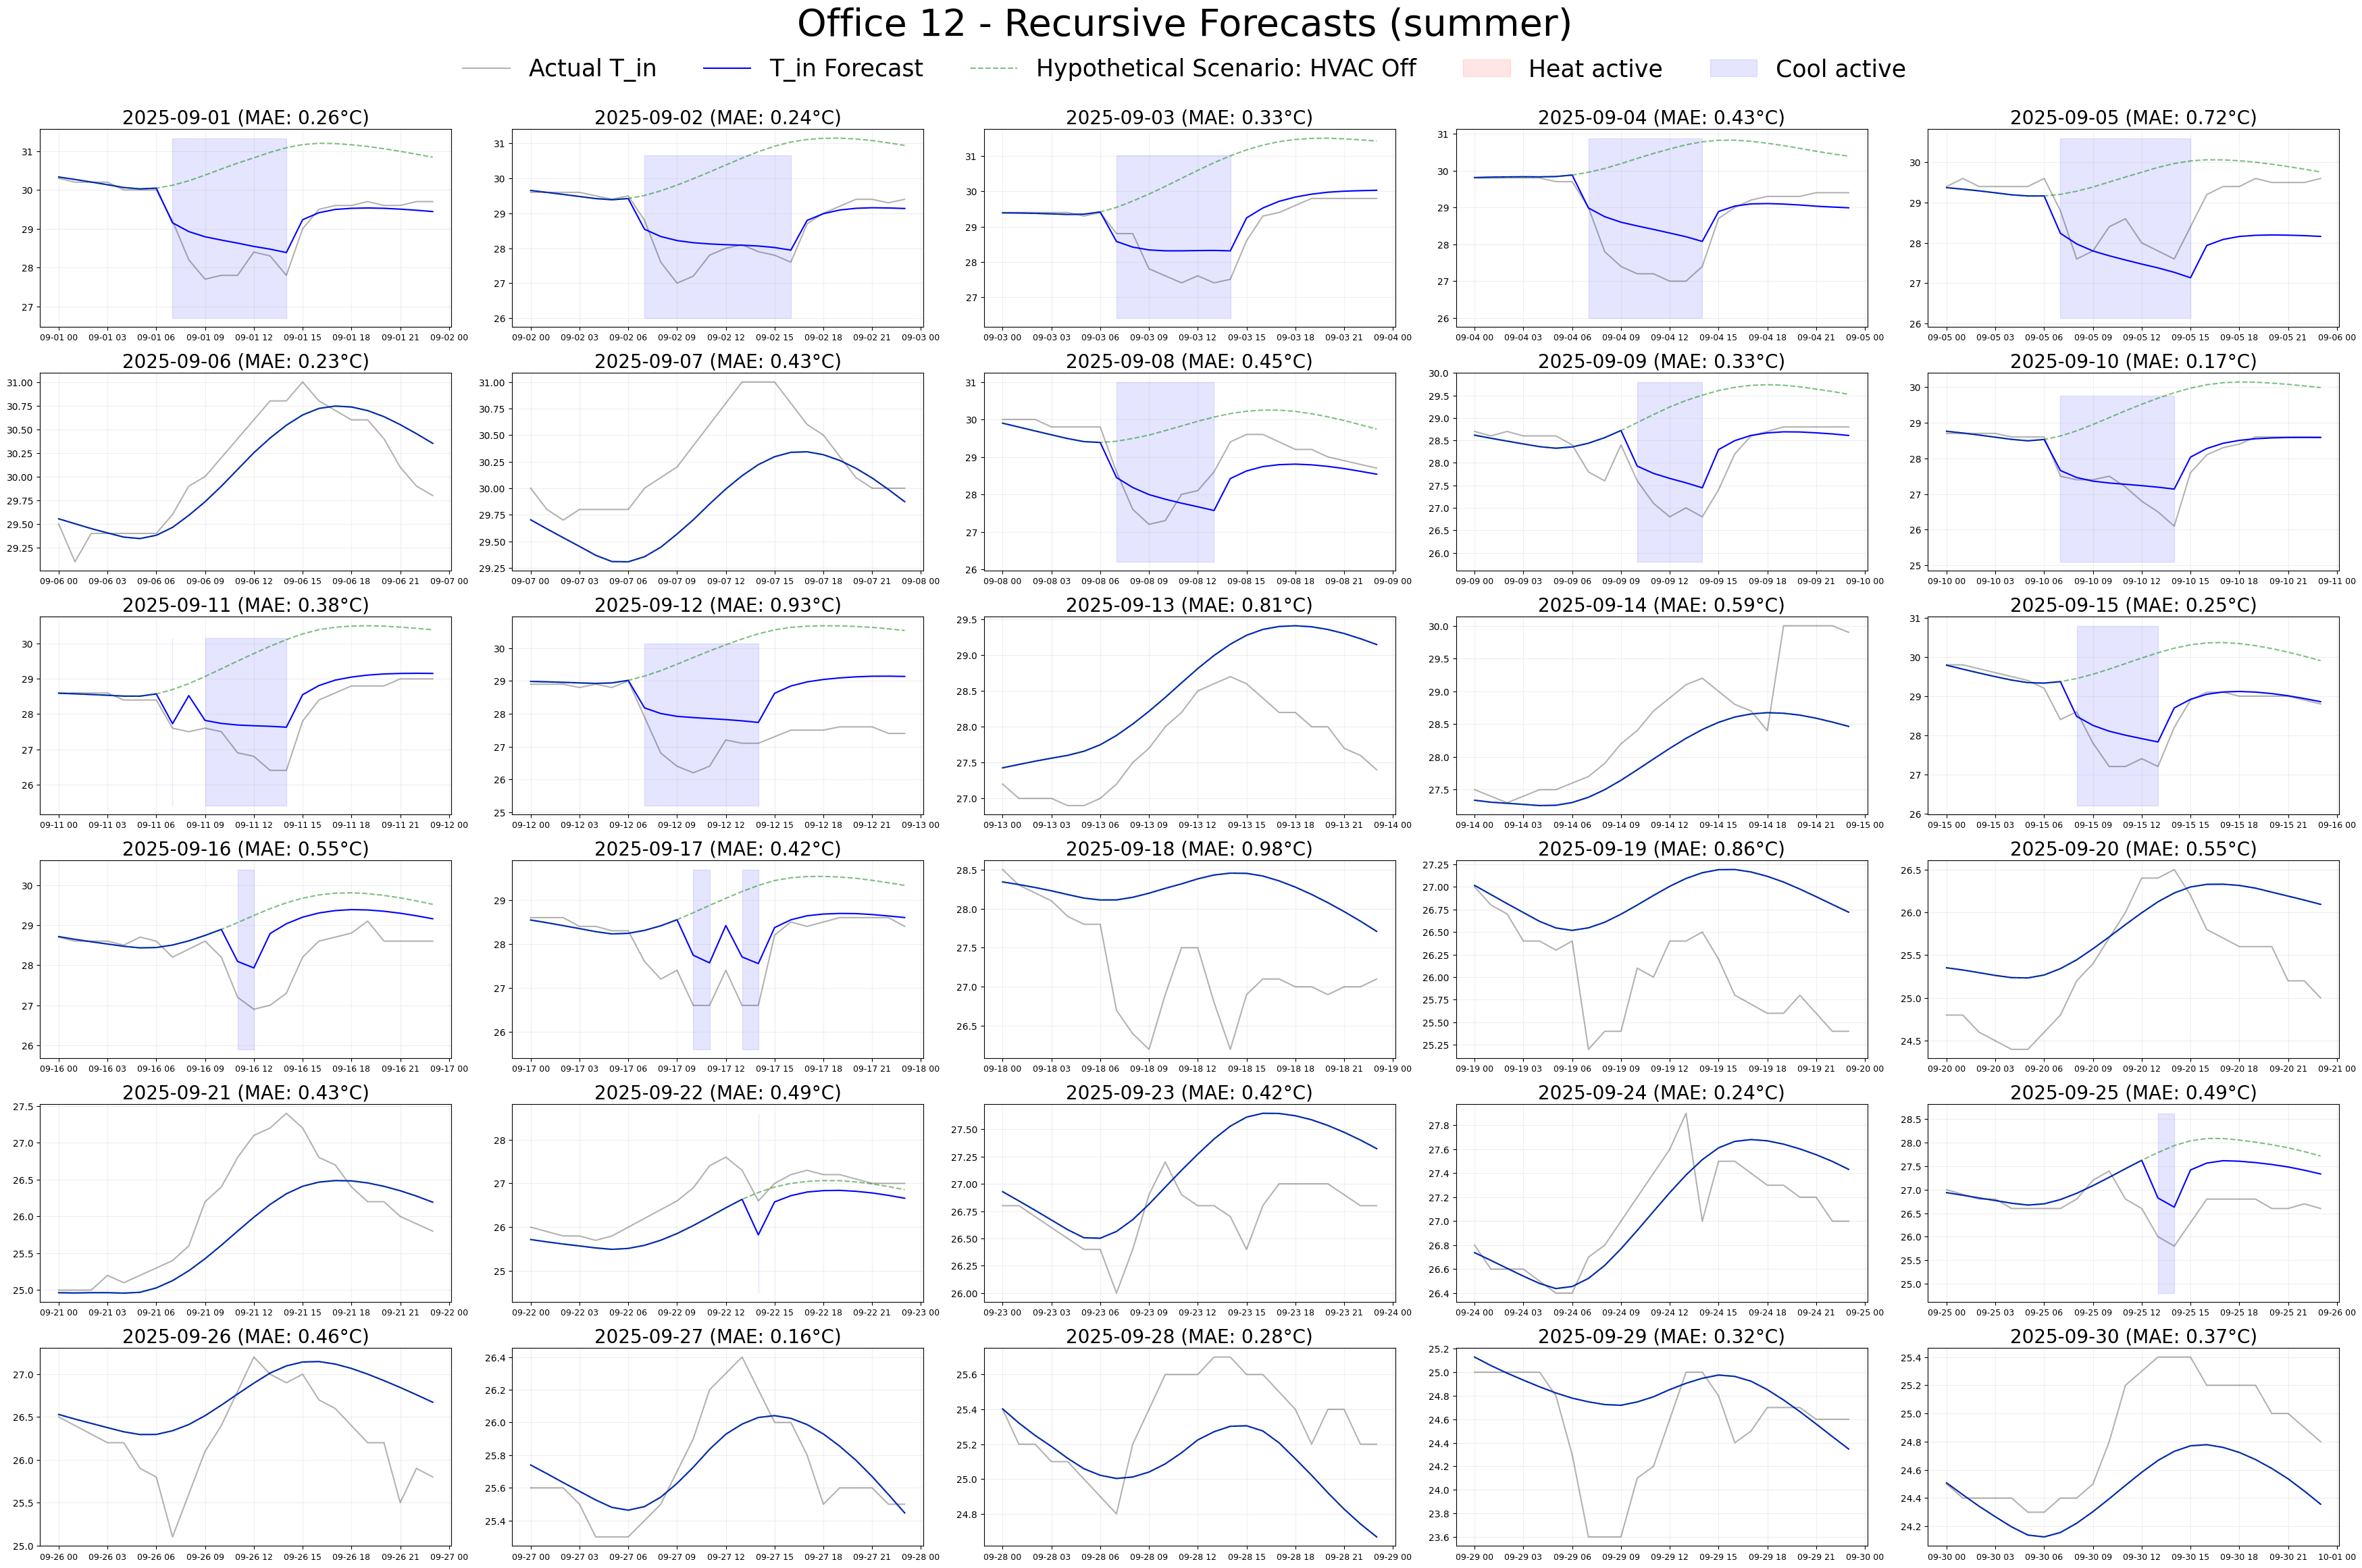

Global Mean MAE (September 2025): 0.453°C


In [ ]:
GRID_NROWS, GRID_NCOLS = 6, 5
sept_days = pd.date_range('2025-09-01', '2025-09-30', freq='D')

fig, axes = plt.subplots(nrows=GRID_NROWS, ncols=GRID_NCOLS, figsize=(7 * GRID_NCOLS, 3.75 * GRID_NROWS))
axes = axes.flatten()

session_maes = []
for s, day in enumerate(sept_days):
    test_start = day.strftime('%Y-%m-%d 00:00')
    day_index = pd.date_range(test_start, periods=horizon, freq='h')
    hist_index = pd.date_range(day_index[0] - pd.Timedelta(hours=24), periods=24, freq='h')

    if not day_index.isin(data_clean.index).all() or not hist_index.isin(data_clean.index).all():
        axes[s].axis('off')
        continue

    session_df = data_clean.loc[day_index].copy()

    initial_history = list(data_clean.loc[hist_index, target_col].values)
    hist_bau, hist_off = initial_history.copy(), initial_history.copy()
    preds_bau, preds_off = [], []
    actuals = session_df[target_col].values

    for i in range(len(session_df)):
        current_row = session_df.iloc[i:i + 1].copy()

        row_bau = current_row.copy()
        (row_bau['t_in_lag1'], row_bau['t_in_lag2'], row_bau['t_in_lag3'], row_bau['t_in_lag24']) = (
            hist_bau[-1], hist_bau[-2], hist_bau[-3], hist_bau[-24]
        )
        p_bau = model.predict(row_bau[feats])[0]
        preds_bau.append(p_bau)
        hist_bau.append(p_bau)

        row_off = current_row.copy()
        row_off['heating_mode'], row_off['cooling_mode'] = 0, 0
        row_off['heating_mode_lag1'], row_off['cooling_mode_lag1'] = 0, 0
        (row_off['t_in_lag1'], row_off['t_in_lag2'], row_off['t_in_lag3'], row_off['t_in_lag24']) = (
            hist_off[-1], hist_off[-2], hist_off[-3], hist_off[-24]
        )
        p_off = model.predict(row_off[feats])[0]
        preds_off.append(p_off)
        hist_off.append(p_off)

    preds_bau_arr = np.array(preds_bau)
    s_mae = mean_absolute_error(actuals, preds_bau)
    session_maes.append(s_mae)

    is_heat = (session_df['heating_mode'] > 0)
    is_cool = (session_df['cooling_mode'] > 0)

    ax = axes[s]
    ax.plot(session_df.index, actuals, color='black', alpha=0.3, label='Actual T_in')
    ax.plot(session_df.index, preds_bau, color='blue', label='T_in Forecast')
    ax.plot(session_df.index, preds_off, color='green', ls='--', alpha=0.5, label='Hypothetical Scenario: HVAC Off')
    y_lims = (min(actuals.min(), preds_bau_arr.min()) - 1, max(actuals.max(), preds_bau_arr.max()) + 1)
    ax.fill_between(session_df.index, *y_lims, where=is_heat, color='red', alpha=0.1, label='Heat active')
    ax.fill_between(session_df.index, *y_lims, where=is_cool, color='blue', alpha=0.1, label='Cool active')
    ax.set_title(f"{day.strftime('%Y-%m-%d')} (MAE: {s_mae:.2f}\u00b0C)", fontsize=20)
    ax.tick_params(axis='x', labelsize=9)
    ax.grid(True, alpha=0.2)

for j in range(len(sept_days), len(axes)):
    axes[j].axis('off')
fig.suptitle(f"Office 12 - Recursive Forecasts (summer)", y=1.03, fontsize=40)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='upper center', bbox_to_anchor=(0.5, 1.01), ncol=5, frameon=False, fontsize=25)
plt.tight_layout()
plt.show()

print(f"Global Mean MAE (September 2025): {np.mean(session_maes):.3f}\u00b0C")


## Office 35

### Train on all data through August 31 and print the linear equation

In [73]:
feats= ['t_in_lag1', 't_in_lag2', 't_in_lag3', 't_out', 't_out_lag1',
        'heating_mode', 'cooling_mode', 'heating_mode_lag1', 'cooling_mode_lag1', 'sin_hour', 'cos_hour']
data_clean = data35_clean
split_date = '2025-09-01'
target_col = 't_in'
horizon = 24

train_df = data_clean.loc[data_clean.index < split_date]
print(f"Training on {len(train_df)} rows, {train_df.index[0]} to {train_df.index[-1]}")

model = LinearRegression()
model.fit(train_df[feats], train_df[target_col])

equation_terms = "\n    + ".join(f"{coef:.2f} * {name}" for coef, name in zip(model.coef_, feats))
print(f"t_in = {model.intercept_:.2f}\n    + {equation_terms}")

Training on 6636 rows, 2024-11-28 12:00:00 to 2025-08-31 23:00:00
t_in = 0.31
    + 1.22 * t_in_lag1
    + -0.19 * t_in_lag2
    + -0.07 * t_in_lag3
    + 0.04 * t_out
    + -0.02 * t_out_lag1
    + 0.50 * heating_mode
    + -1.08 * cooling_mode
    + -0.26 * heating_mode_lag1
    + 0.88 * cooling_mode_lag1
    + 0.06 * sin_hour
    + -0.05 * cos_hour


### Recursive forecast evaluation — every day of September (30 independent 24h forecasts)

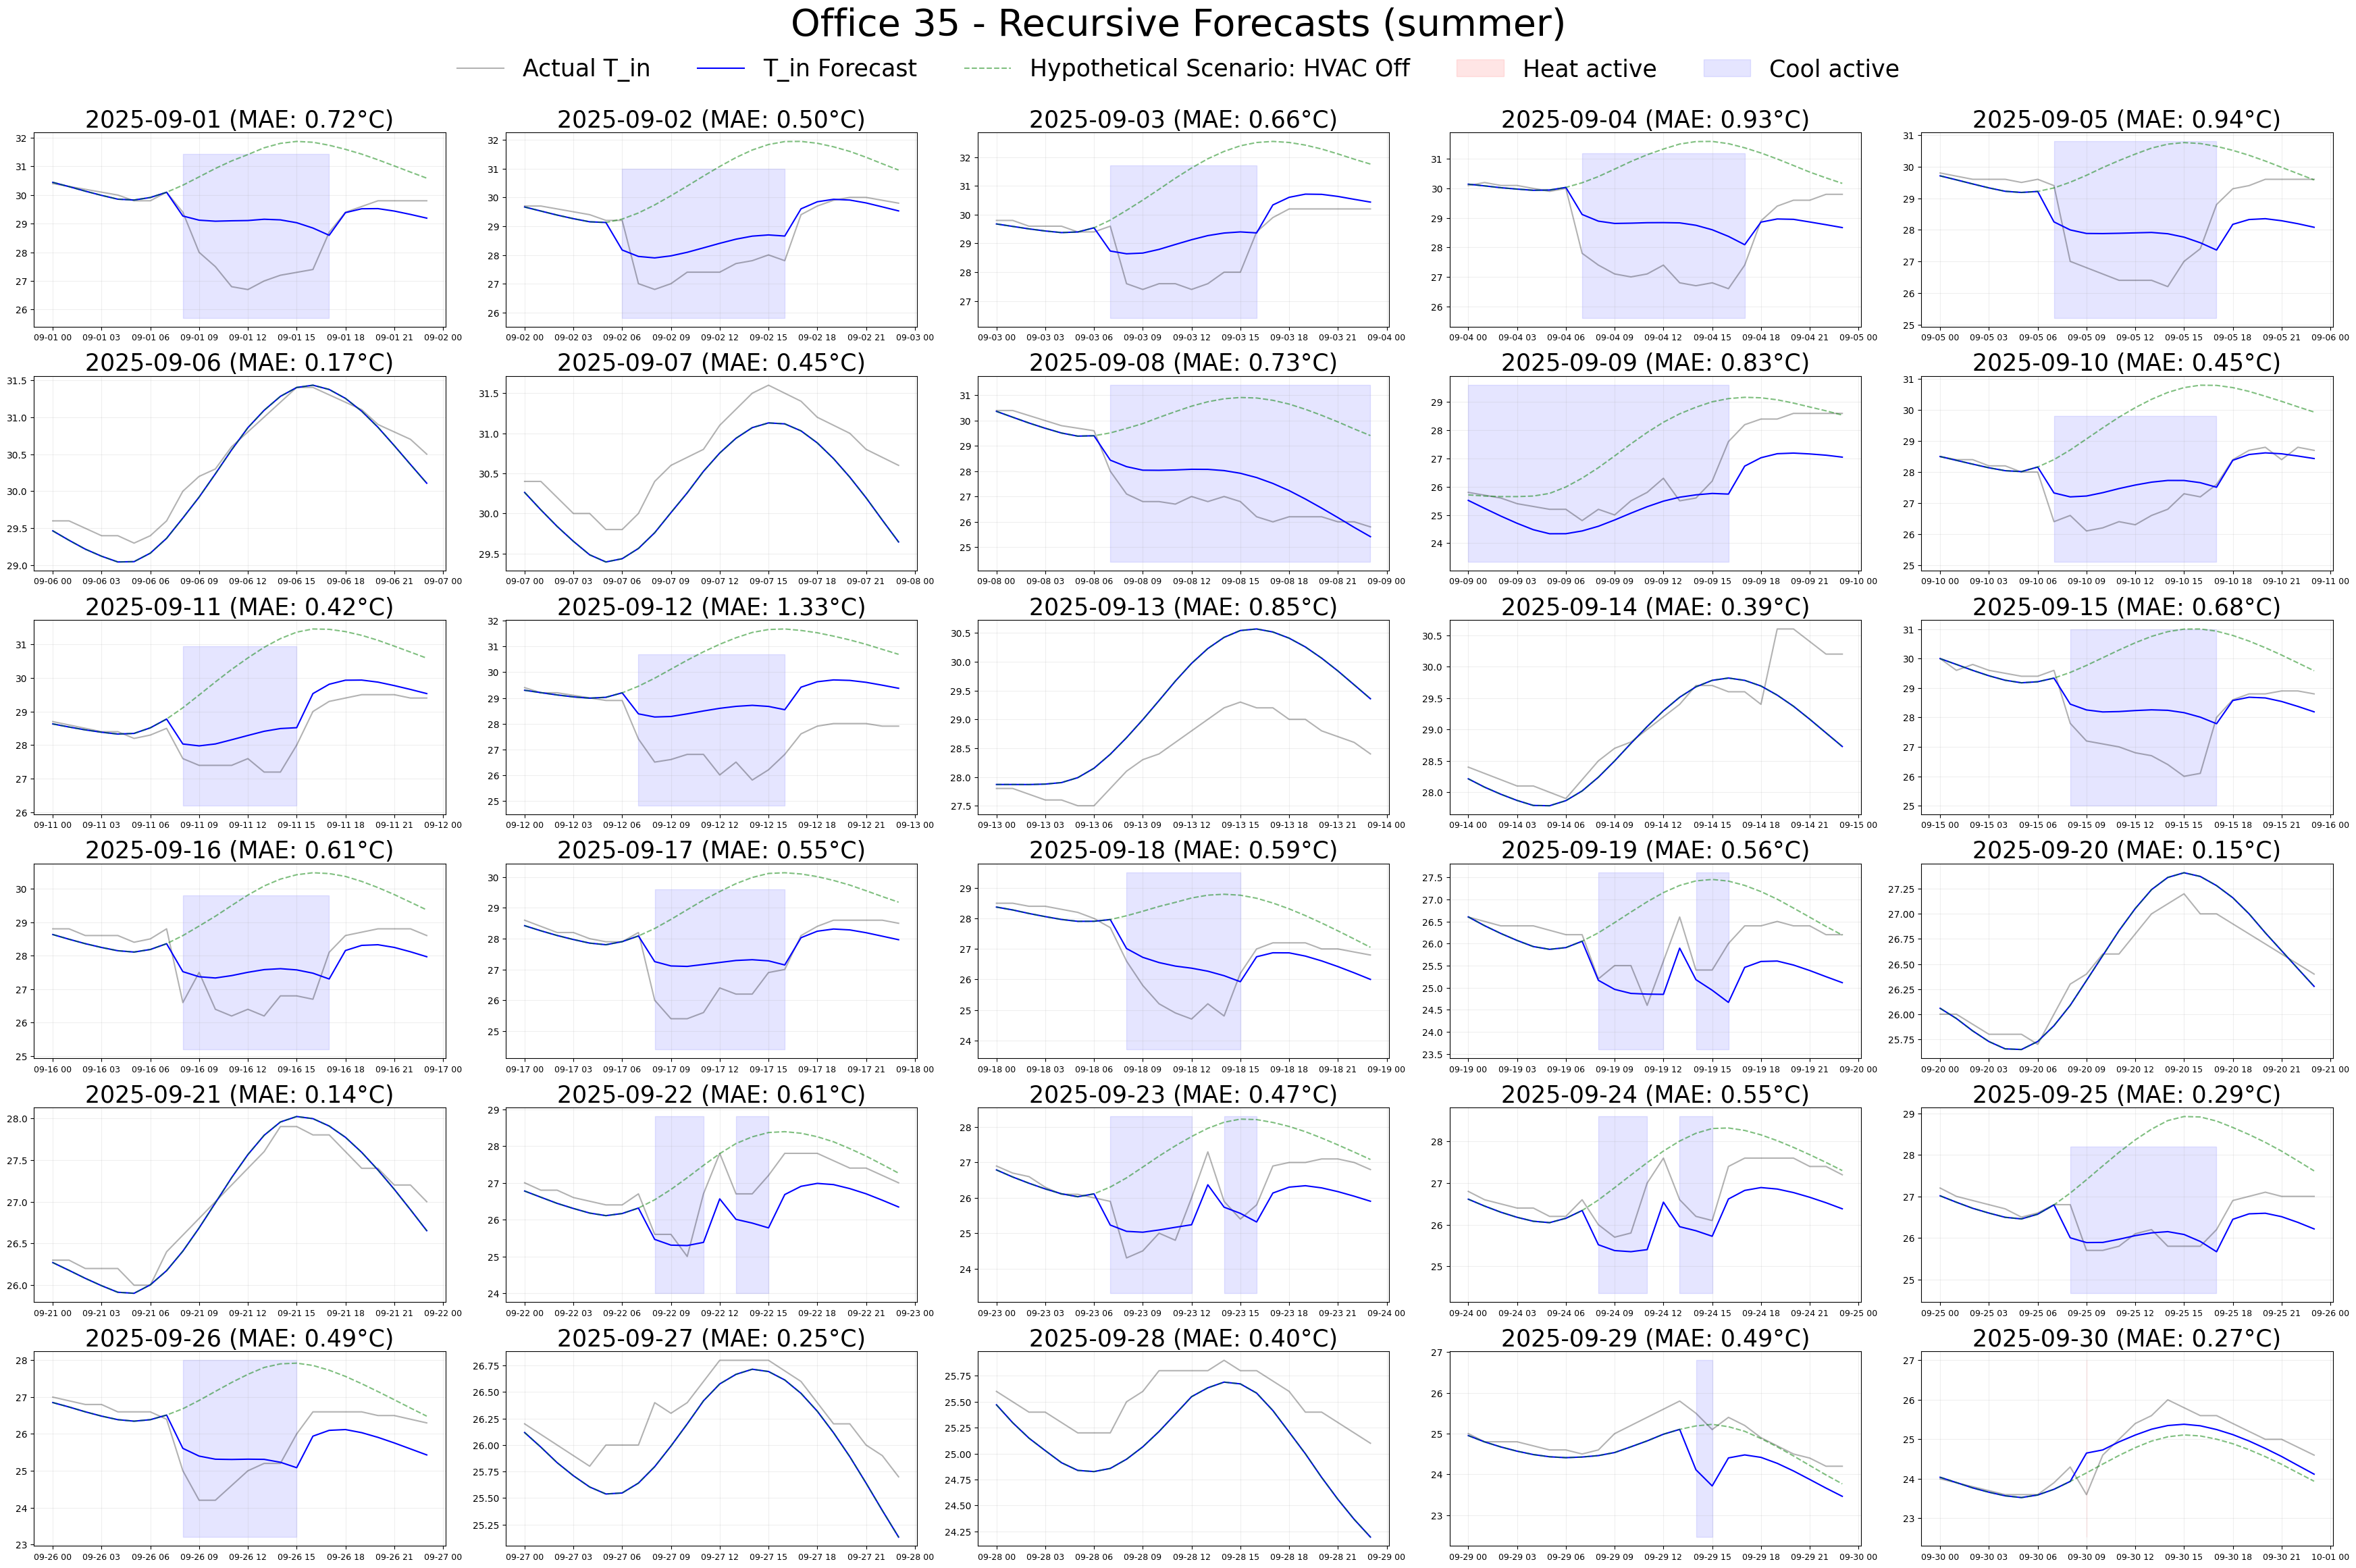

Global Mean MAE (September 2025): 0.549°C


In [ ]:
GRID_NROWS, GRID_NCOLS = 6, 5
sept_days = pd.date_range('2025-09-01', '2025-09-30', freq='D')

fig, axes = plt.subplots(nrows=GRID_NROWS, ncols=GRID_NCOLS, figsize=(7 * GRID_NCOLS, 3.75 * GRID_NROWS))
axes = axes.flatten()

session_maes = []
for s, day in enumerate(sept_days):
    test_start = day.strftime('%Y-%m-%d 00:00')
    day_index = pd.date_range(test_start, periods=horizon, freq='h')
    hist_index = pd.date_range(day_index[0] - pd.Timedelta(hours=24), periods=24, freq='h')

    if not day_index.isin(data_clean.index).all() or not hist_index.isin(data_clean.index).all():
        axes[s].axis('off')
        continue

    session_df = data_clean.loc[day_index].copy()

    initial_history = list(data_clean.loc[hist_index, target_col].values)
    hist_bau, hist_off = initial_history.copy(), initial_history.copy()
    preds_bau, preds_off = [], []
    actuals = session_df[target_col].values

    for i in range(len(session_df)):
        current_row = session_df.iloc[i:i + 1].copy()

        row_bau = current_row.copy()
        (row_bau['t_in_lag1'], row_bau['t_in_lag2'], row_bau['t_in_lag3'], row_bau['t_in_lag24']) = (
            hist_bau[-1], hist_bau[-2], hist_bau[-3], hist_bau[-24]
        )
        p_bau = model.predict(row_bau[feats])[0]
        preds_bau.append(p_bau)
        hist_bau.append(p_bau)

        row_off = current_row.copy()
        row_off['heating_mode'], row_off['cooling_mode'] = 0, 0
        row_off['heating_mode_lag1'], row_off['cooling_mode_lag1'] = 0, 0
        (row_off['t_in_lag1'], row_off['t_in_lag2'], row_off['t_in_lag3'], row_off['t_in_lag24']) = (
            hist_off[-1], hist_off[-2], hist_off[-3], hist_off[-24]
        )
        p_off = model.predict(row_off[feats])[0]
        preds_off.append(p_off)
        hist_off.append(p_off)

    preds_bau_arr = np.array(preds_bau)
    s_mae = mean_absolute_error(actuals, preds_bau)
    session_maes.append(s_mae)

    is_heat = (session_df['heating_mode'] > 0)
    is_cool = (session_df['cooling_mode'] > 0)
    
    ax = axes[s]
    ax.plot(session_df.index, actuals, color='black', alpha=0.3, label='Actual T_in')
    ax.plot(session_df.index, preds_bau, color='blue', label='T_in Forecast')
    ax.plot(session_df.index, preds_off, color='green', ls='--', alpha=0.5, label='Hypothetical Scenario: HVAC Off')
    y_lims = (min(actuals.min(), preds_bau_arr.min()) - 1, max(actuals.max(), preds_bau_arr.max()) + 1)
    ax.fill_between(session_df.index, *y_lims, where=is_heat, color='red', alpha=0.1, label='Heat active')
    ax.fill_between(session_df.index, *y_lims, where=is_cool, color='blue', alpha=0.1, label='Cool active')
    ax.set_title(f"{day.strftime('%Y-%m-%d')} (MAE: {s_mae:.2f}\u00b0C)", fontsize=25)
    ax.tick_params(axis='x', labelsize=9)
    ax.grid(True, alpha=0.2)

for j in range(len(sept_days), len(axes)):
    axes[j].axis('off')
fig.suptitle(f"Office 35 - Recursive Forecasts (summer)", y=1.03, fontsize=40)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='upper center', bbox_to_anchor=(0.5, 1.01), ncol=5, frameon=False, fontsize=25)
plt.tight_layout()
plt.show()

print(f"Global Mean MAE (September 2025): {np.mean(session_maes):.3f}\u00b0C")

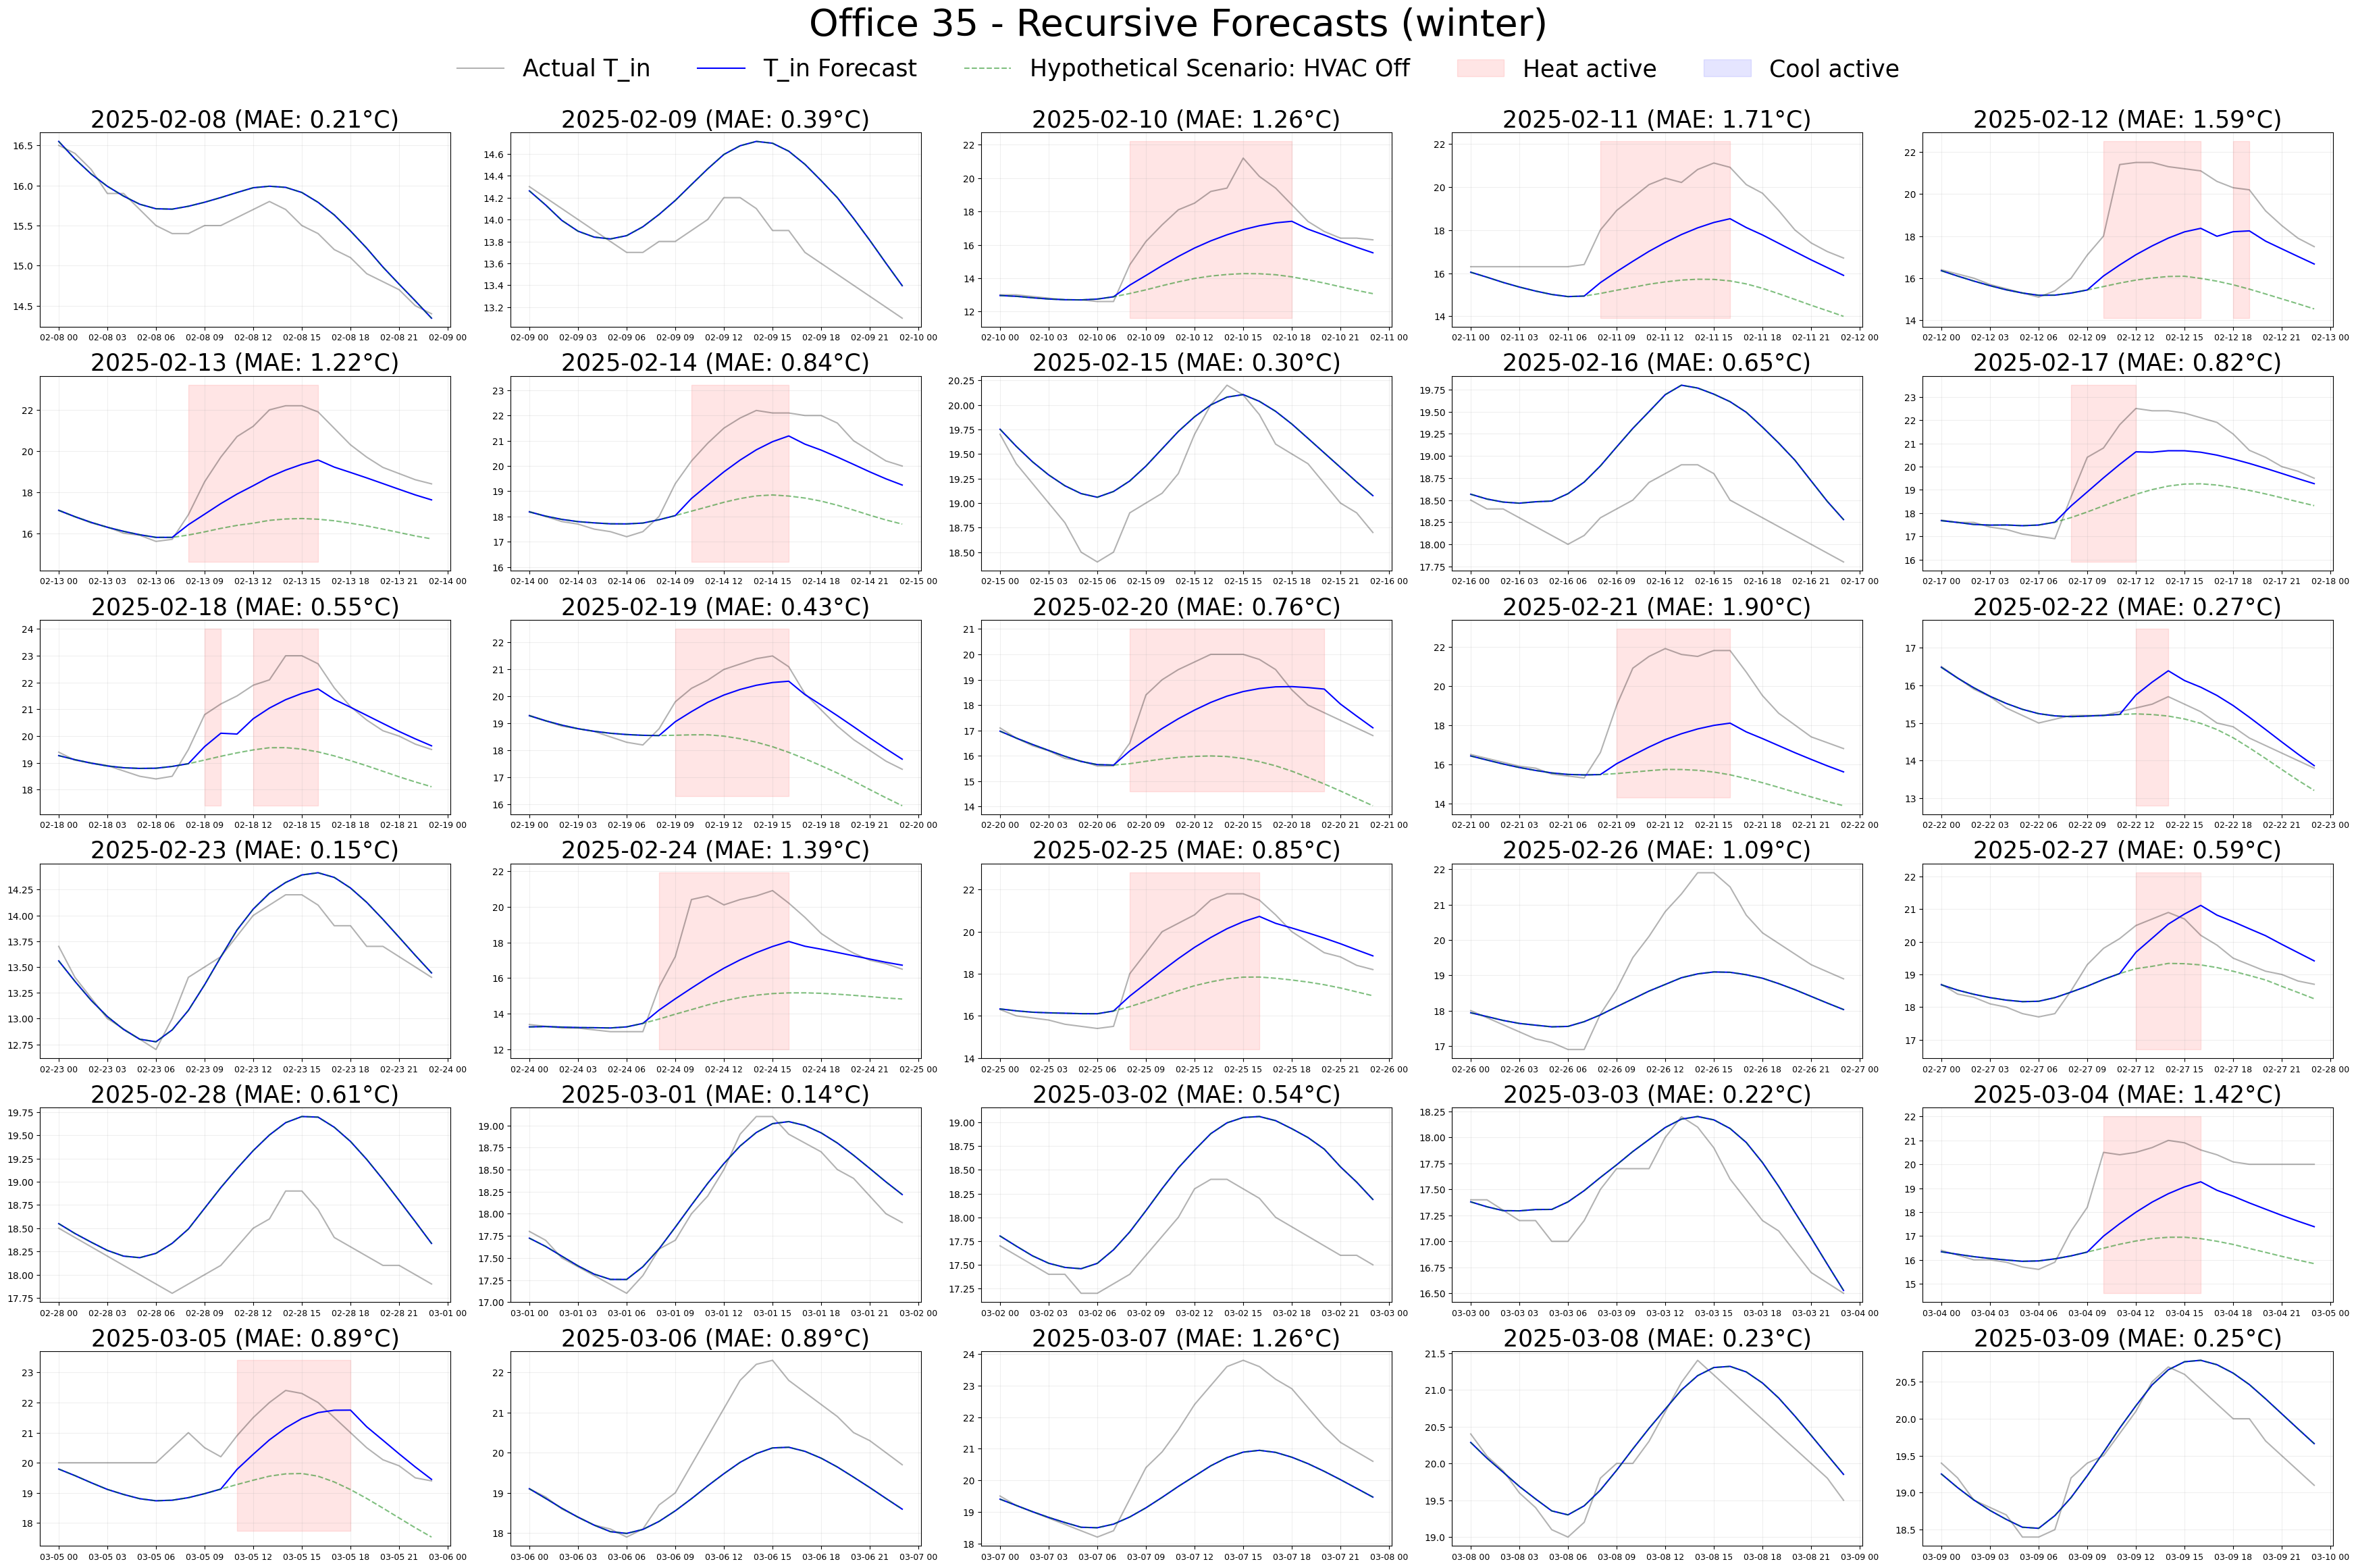

Global Mean MAE (Feb 2025): 0.781°C


In [ ]:
GRID_NROWS, GRID_NCOLS = 6, 5
winter_days = pd.date_range('2025-02-08', '2025-03-09', freq='D')

fig, axes = plt.subplots(nrows=GRID_NROWS, ncols=GRID_NCOLS, figsize=(7 * GRID_NCOLS, 3.75 * GRID_NROWS))
axes = axes.flatten()

session_maes = []
for s, day in enumerate(winter_days):
    test_start = day.strftime('%Y-%m-%d 00:00')
    day_index = pd.date_range(test_start, periods=horizon, freq='h')
    hist_index = pd.date_range(day_index[0] - pd.Timedelta(hours=24), periods=24, freq='h')

    if not day_index.isin(data_clean.index).all() or not hist_index.isin(data_clean.index).all():
        axes[s].axis('off')
        continue

    session_df = data_clean.loc[day_index].copy()

    initial_history = list(data_clean.loc[hist_index, target_col].values)
    hist_bau, hist_off = initial_history.copy(), initial_history.copy()
    preds_bau, preds_off = [], []
    actuals = session_df[target_col].values

    for i in range(len(session_df)):
        current_row = session_df.iloc[i:i + 1].copy()

        row_bau = current_row.copy()
        (row_bau['t_in_lag1'], row_bau['t_in_lag2'], row_bau['t_in_lag3'], row_bau['t_in_lag24']) = (
            hist_bau[-1], hist_bau[-2], hist_bau[-3], hist_bau[-24]
        )
        p_bau = model.predict(row_bau[feats])[0]
        preds_bau.append(p_bau)
        hist_bau.append(p_bau)

        row_off = current_row.copy()
        row_off['heating_mode'], row_off['cooling_mode'] = 0, 0
        row_off['heating_mode_lag1'], row_off['cooling_mode_lag1'] = 0, 0
        (row_off['t_in_lag1'], row_off['t_in_lag2'], row_off['t_in_lag3'], row_off['t_in_lag24']) = (
            hist_off[-1], hist_off[-2], hist_off[-3], hist_off[-24]
        )
        p_off = model.predict(row_off[feats])[0]
        preds_off.append(p_off)
        hist_off.append(p_off)

    preds_bau_arr = np.array(preds_bau)
    s_mae = mean_absolute_error(actuals, preds_bau)
    session_maes.append(s_mae)

    is_heat = (session_df['heating_mode'] > 0)
    is_cool = (session_df['cooling_mode'] > 0)

    ax = axes[s]
    ax.plot(session_df.index, actuals, color='black', alpha=0.3, label='Actual T_in')
    ax.plot(session_df.index, preds_bau, color='blue', label='T_in Forecast')
    ax.plot(session_df.index, preds_off, color='green', ls='--', alpha=0.5, label='Hypothetical Scenario: HVAC Off')
    y_lims = (min(actuals.min(), preds_bau_arr.min()) - 1, max(actuals.max(), preds_bau_arr.max()) + 1)
    ax.fill_between(session_df.index, *y_lims, where=is_heat, color='red', alpha=0.1, label='Heat active')
    ax.fill_between(session_df.index, *y_lims, where=is_cool, color='blue', alpha=0.1, label='Cool active')
    ax.set_title(f"{day.strftime('%Y-%m-%d')} (MAE: {s_mae:.2f}\u00b0C)", fontsize=25)
    ax.tick_params(axis='x', labelsize=9)
    ax.grid(True, alpha=0.2)

for j in range(len(winter_days), len(axes)):
    axes[j].axis('off')
fig.suptitle(f"Office 35 - Recursive Forecasts (winter)", y=1.03, fontsize=40)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='upper center', bbox_to_anchor=(0.5, 1.01), ncol=5, frameon=False, fontsize=25)
plt.tight_layout()
plt.show()

print(f"Global Mean MAE (Feb 2025): {np.mean(session_maes):.3f}\u00b0C")